# Spectral Clustering


In this exercise, you will implement spectral clustering and try it on diffent kinds of data, for instance:

* N-blob: Random points in $\mathbb{R}^2$ according to N Gaussian distributions with different means;

* Two moons: Random points shaped as two intertwined moons; 

* Point and circle: random points from a concentrated Gaussian point in the middle and a wide circle around it.

The first step after generating the data is to construct a graph and, for that, we need a similarity function. In this exercise we will use the following similarity:

$$
d(x_i, x_j) = \exp\left(-\frac{||x_i-x_j||_2^2}{2\sigma^2}\right)
$$

Using this similarity, we can compute the weight matrix W representing the graph, compute the graph Laplacian L and finally use its eigenvectors for clustering.


## Setup

In [1]:
from generate_data import worst_case_blob, blobs, two_moons, point_and_circle
from utils import plot_clusters, min_span_tree, plot_graph_matrix, min_span_tree
from utils import plot_clustering_result, plot_the_bend
from sklearn.cluster import KMeans
import sklearn.metrics as skm
import numpy as np
from skimage import io
import numpy as np
import matplotlib.pyplot as plt
import os

## Generating the data

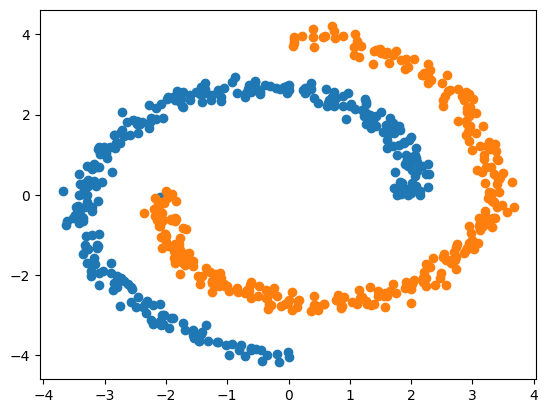

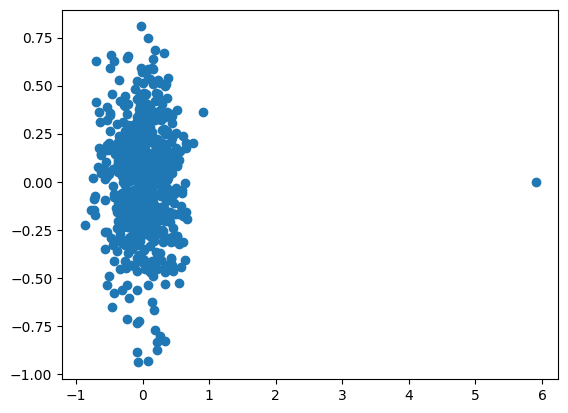

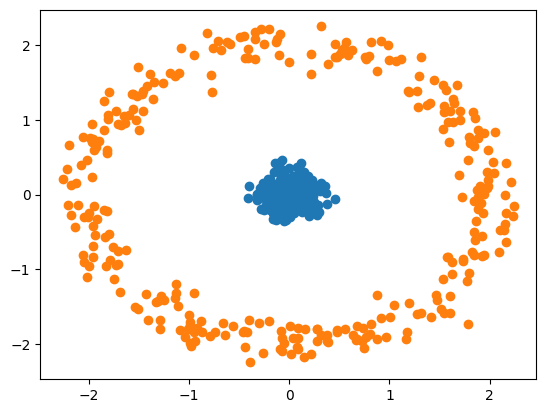

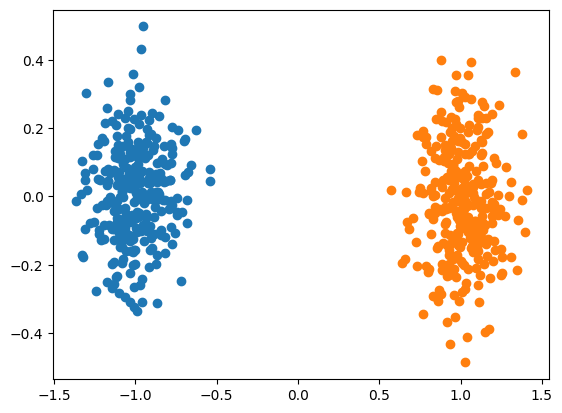

In [2]:
# Example

# for fn in [two_moons]:  #  try also [worst_case_blob, point_and_circle, blobs]
for fn in [two_moons, worst_case_blob, point_and_circle, blobs]:  #  try also [worst_case_blob, point_and_circle, blobs]
    X, Y = fn(num_samples=600)
    plot_clusters(X, Y, fignum=str(fn))
    
# You can check the documentation of each function to see the optional parameters, e.g.:
# worst_case_blob?

## Building similarity graph

In [3]:
def build_similarity_graph(X, var=1.0, eps=0.0, k=0):
    """
    TO BE COMPLETED.

    Computes the similarity matrix for a given dataset of samples. 
    If k=0, builds epsilon graph. 
    Otherwise, builds kNN graph.

    Parameters
    ----------
    X : numpy array
        (n x m) matrix of m-dimensional samples
    var : double 
        the sigma value for the exponential function, already squared
    eps : double
        threshold for epsilon graphs
    k : int
        The number of neighbours k for k-nn. If zero, use epsilon-graph

    Returns
    -------
        W: (n x n) dimensional matrix representing the weight matrix of the graph
    """
    n = X.shape[0]
    W = np.zeros((n, n))

    """
    Build similarity graph, before threshold or kNN
    similarities: (n x n) matrix with similarities between all possible couples of points.
    The similarity function is d(x,y)=exp(-||x-y||^2/(2*var))
    """

    distance = skm.euclidean_distances(X, squared=True)
    similarities = np.exp(-distance/(2*var))
    np.fill_diagonal(similarities, 0) # we remove the self-similarities

    # If epsilon graph
    if k == 0:
        """
        compute an epsilon graph from the similarities             
        for each node x_i, an epsilon graph has weights             
        w_ij = d(x_i,x_j) when w_ij >= eps, and 0 otherwise          
        """
        W = np.where(similarities >= eps, similarities, 0)

    # If kNN graph
    elif k != 0:
        """
        compute a k-nn graph from the similarities                   
        for each node x_i, a k-nn graph has weights                  
        w_ij = d(x_i,x_j) for the k closest nodes to x_i, and 0     
        for all the k-n remaining nodes                              
        Remember to remove self similarity and                       
        make the graph undirected                                    
        """
        for i in range(n):
            k_closest_indices = np.argsort(similarities[i])[-k:]
            W[i, k_closest_indices] = similarities[i, k_closest_indices]

        W = np.maximum(W, W.T) # make graph undirected. If one of two directions is 0, take the other value for symmetry
    return W


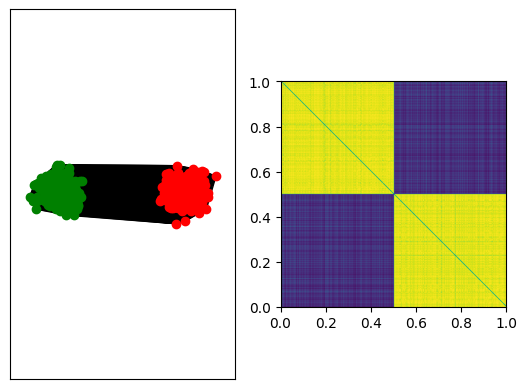

In [45]:
# Example

W = build_similarity_graph(X)
W[0, 599] = 1    # add two placeholder edges to reproduce example picture
W[10, 500] = 1   # 


plot_graph_matrix(X, Y, W)  # shows the graph and the visualization of W

## Computing the Laplacian

In [4]:
def build_laplacian(W, laplacian_normalization='unn'):
    """
    Compute graph Laplacian.

    Parameters
    ----------
    W : numpy array
        Adjacency matrix (n x n)
    laplacian_normalization : str
        String selecting which version of the laplacian matrix to construct.
            'unn':  unnormalized,
            'sym': symmetric normalization
            'rw':  random-walk normalization   

    Returns
    -------
    L: (n x n) dimensional matrix representing the Laplacian of the graph
    """
    L = np.zeros(W.shape)
    degrees = np.sum(W, axis=1)
    
    if laplacian_normalization == 'unn': # (unnormalized): L = D - W
        D = np.diag(degrees) # diags(degrees, format='csr') if we wanted sparsity
        L = D - W
    elif laplacian_normalization == 'sym': # (symmetric normalization): L = I - D^(-1/2) W D^(-1/2)
        D_inv = np.diag(1.0/np.sqrt(degrees + 1e-12)) 
        L = np.eye(W.shape[0]) - D_inv @ W @ D_inv # I = eye(W.shape[0], format='csr') if we wanted sparsity
    elif laplacian_normalization == 'rw': # (random-walk normalization): L = I - D^(-1) W
        D_inv = np.diag(1.0/(degrees + 1e-12))
        L = np.eye(W.shape[0]) - D_inv @ W
    return L

## Clustering

In [5]:
def plot_eigenvalues(eigenvalues, chosen_eig_indices):
    """
    Parameters
    ----------
    eigenvalues : numpy array
        Eigenvalues of the graph
    choosen_eig_indices : list
        Indices of eigenvectors to use for clustering. 
    """

    """
    A function to plot the eigenvalues of the graph, alongside the chosen eigenvalues for clustering.
    """
    _, ax = plt.subplots(1, 1, figsize=(5, 2.5))
    n = 10 # how may eigenvalues to show

    eigenvalues = np.asarray(eigenvalues).ravel()[:n]
    chosen_eig_indices = np.asarray(chosen_eig_indices)[:n]

    x_axis = np.arange(1, n+1)

    ax.plot(
        x_axis,
        eigenvalues[:n], 
        linestyle="None", 
        marker="*", 
        markersize=6
    )

    ax.plot(
        chosen_eig_indices + 1,
        eigenvalues[chosen_eig_indices],
        linestyle="None", 
        marker="D", 
        markersize=4
    )

    ax.set_xlabel("Eigenvalues")
    ax.set_xlim(1, n)
    ax.grid(False)
    ax.legend(["Eigenvalues", "Chosen eigenvalues"], loc="lower right")

    plt.tight_layout()
    plt.show()

In [ ]:
def spectral_clustering(L, chosen_eig_indices=None, num_classes=2, plot_eig=True, use_sparse_and_lanczos=False):
    """
    Parameters
    ----------
    L : numpy array
        Graph Laplacian (standard or normalized)
    choosen_eig_indices : list or None
        Indices of eigenvectors to use for clustering. 
        If None, use adaptive choice of eigenvectors.
    num_classes : int 
        Number of clusters to compute (defaults to 2)
    plot_eig: bool
        Flag to plot the eigenvalues using the function plot_eigenvalues.
    use_sparse_and_lanczos: bool
        Flag to use sparse matrices and eigsh for eigen decomposition.
        Not in use.


    Returns
    -------
    Y : numpy array (num_samples, )
        Cluster assignments
    """

    """
    Use the function scipy.linalg.eig or the function scipy.sparse.linalg.eigs to compute:
    U = (n x n) eigenvector matrix           (sorted)
    E = (n x n) eigenvalue diagonal matrix   (sorted)
    """
    # code for q3.2 and q3.3
    # if use_sparse_and_lanczos:
    #     from scipy.sparse.linalg import eigsh
    #     from scipy.sparse import csr_matrix
    #     if not hasattr(L, "tocsr"):
    #         print("NOT CSR")
    #         L = csr_matrix(L)
    #     eigenvalues, eigenvectors = eigsh(L, k=num_classes, which='SM')

    # if not use_sparse_and_lanczos:

    from scipy.linalg import eig
    eigenvalues, eigenvectors = eig(L)
    eigenvalues = eigenvalues.real
    eigenvectors = eigenvectors.real

    sorted_eig_indices = np.argsort(eigenvalues)
    eigenvalues = eigenvalues[sorted_eig_indices]
    eigenvectors = eigenvectors[:, sorted_eig_indices]

    if chosen_eig_indices is None:
        end_index = min(10, len(eigenvalues) - 1) # limit to first 10 eigenvalues for better eigengap heuristic
        gaps = eigenvalues[1:end_index] - eigenvalues[:end_index-1]
        k = int(np.argmax(gaps) + 1) # take the index of the largest gap + 1
        chosen_eig_indices = np.arange(k)

    E = np.diag(eigenvalues[chosen_eig_indices])
    U = eigenvectors[:, chosen_eig_indices]

    if plot_eig:
        plot_eigenvalues(eigenvalues, chosen_eig_indices)

    """
    compute the clustering assignment from the eigenvectors        
    Y = (n x 1) cluster assignments in [0,1,...,num_classes-1]                   
    """
    Y = KMeans(n_clusters=num_classes, random_state=42).fit_predict(U)
    return Y, eigenvalues, eigenvectors # return eigen values and vectors for plotting and analysis

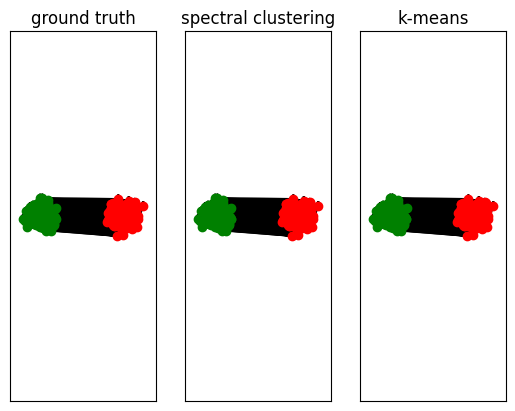

In [ ]:
# Example

num_classes = 2
L = build_laplacian(W)
Y_rec = spectral_clustering(L, chosen_eig_indices=[1], num_classes=num_classes)

# Plot results, comparing to KMeans
plot_clustering_result(X, Y, L, Y_rec, KMeans(num_classes).fit_predict(X))

## Parameter sensitivity 

In [ ]:
def parameter_sensitivity():
    """
    TO BE COMPLETED.

    A function to test spectral clustering sensitivity to parameter choice.
    """
    # the number of samples to generate
    num_samples = 500

    """
    Choose parameters
    """
    var = 1.0  # exponential_euclidean's sigma^2
    laplacian_normalization = 'rw'
    chosen_eig_indices = None

    X, Y = two_moons(num_samples, 1, 0.02)
    num_classes = len(np.unique(Y))

    """
    Choose candidate parameters
    """
    parameter_type = 'k' # choose between 'k' or 'eps'
    parameter_candidate = list(range(2, 50, 2))
    parameter_performance = []

    for parameter in parameter_candidate:
        # Generate data              
        parameter_wrap = {parameter_type: parameter}
        
        W = build_similarity_graph(X, **parameter_wrap)
        L = build_laplacian(W, laplacian_normalization)

        Y_rec, _, _ = spectral_clustering(L, chosen_eig_indices, num_classes, plot_eig=False)
        parameter_performance += [skm.adjusted_rand_score(Y, Y_rec)]

    plt.figure()
    plt.plot(parameter_candidate, parameter_performance)
    plt.title(f'parameter sensitivity ({parameter_type})')
    plt.show()

    """
    Choose candidate parameters
    """
    parameter_type = 'eps' # choose between 'k' or 'eps'
    parameter_candidate = np.linspace(0.01, 1, 20)
    parameter_performance = []

    for parameter in parameter_candidate:
        # Generate data              
        parameter_wrap = {parameter_type: parameter}
        
        W = build_similarity_graph(X, **parameter_wrap)
        L = build_laplacian(W, laplacian_normalization)

        Y_rec, _, _ = spectral_clustering(L, chosen_eig_indices, num_classes, plot_eig=False)
        parameter_performance += [skm.adjusted_rand_score(Y, Y_rec)]

    plt.figure()
    plt.plot(parameter_candidate, parameter_performance)
    plt.title(f'parameter sensitivity ({parameter_type})')
    plt.show()

## Image segmentation

In [ ]:
from skimage.transform import resize

def image_segmentation(
        input_img='four_elements.bmp',
        var=1.0,
        k=2,
        laplacian_normalization='unn',
        num_classes=1,
        chosen_eig_indices=None,
        plot_eig=True,
        downsample_img=False,
        use_sparse_and_lanczos=False
    ):
    """
    TO BE COMPLETED

    Function to perform image segmentation.

    :param input_img: name of the image file in /data (e.g. 'four_elements.bmp' or 'fruit_salad.bmp')
    """
    filename = os.path.join('data', input_img)

    X = io.imread(filename)

    # downsampling logic. Keep the original image for final visualization and downsample for faster clustering.
    original_X = X.copy()
    if downsample_img:
        X = resize(X, (50, 50), anti_aliasing=True, preserve_range=True)

    X = (X - np.min(X)) / (np.max(X) - np.min(X))

    im_side = np.size(X, 1)
    Xr = X.reshape(im_side ** 2, 3)
    """
    Y_rec should contain an index from 0 to c-1 where c is the     
     number of segments you want to split the image into          
    """

    """
    Choose parameters
    """

    W = build_similarity_graph(Xr, var=var, k=k)
    L = build_laplacian(W, laplacian_normalization)
    Y_rec, _, _ = spectral_clustering(L, chosen_eig_indices, num_classes=num_classes, plot_eig=plot_eig, use_sparse_and_lanczos=use_sparse_and_lanczos)

    # plot downsampled image
    Y_rec = Y_rec.reshape(im_side, im_side)
    if downsample_img:
        plt.figure()
        plt.subplot(1, 2, 1)
        plt.imshow(X)
        plt.subplot(1, 2, 2)
        plt.title("Downsampled segmentation")
        Y_rec = Y_rec.reshape(im_side, im_side)
        plt.imshow(Y_rec)

        # upsample the segmentation back to original size
        Y_rec = resize(Y_rec, (np.size(original_X, 1), np.size(original_X, 1)), order=0, anti_aliasing=False, preserve_range=True)
    
    plt.figure()

    plt.subplot(1, 2, 1)
    plt.imshow(original_X)
    if downsample_img:
        plt.title("Original size segmentation")

    plt.subplot(1, 2, 2)
    
    plt.imshow(Y_rec)

    plt.show()

your avg degree: 33.30125946049987


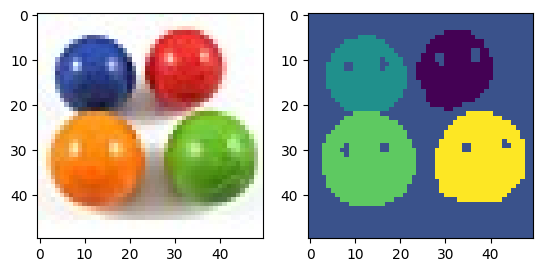

In [68]:
image_segmentation(k=26, laplacian_normalization='unn', num_classes=5, chosen_eig_indices=[1, 2, 3, 4, 5])


# Questions

### Q1.1: What is the purpose of the option parameter in `worst_case_blob`?

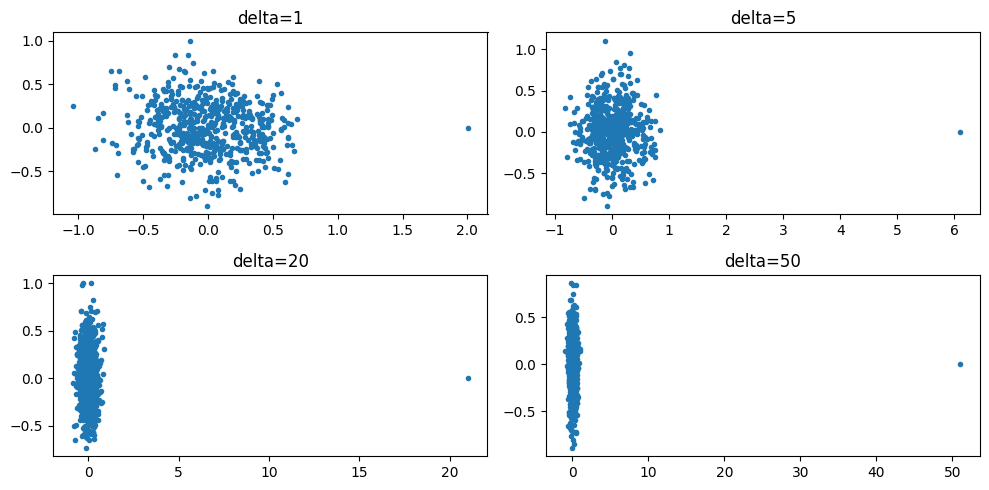

In [21]:
_, ax = plt.subplots(2, 2, figsize=(10, 5))
ax = ax.flatten()

for i, delta in enumerate([1, 5, 20, 50]):
    X, _ = worst_case_blob(num_samples=600, delta=delta)
    ax[i].plot(X[:, 0], X[:, 1], '.')
    ax[i].set_title(f"delta={delta}")

plt.tight_layout()
plt.show()

The purpose of the `delta` parameter is to create an outlier in this 2D Gaussian distribution. This outlier is obtained by translation of the sample with the largest coordinate value along x-axis by value of `delta`. Its y-coordinate is set to zero.

### Q1.2: While varying the parameter of `worst_case_blob`, try to select a value of $\epsilon$ that keeps the graph connected (the function `min_span_tree` can help you). What happens? Can you tell when it is a bad idea to use this approach?

In [22]:
min_span_tree?

Signature: min_span_tree(W)
Docstring:
:param W: (n x n) adjacency matrix representing the graph
:return: T: (n x n) matrix such that T[i,j] = True if the edge (i, j) is in the min spanning tree, and
            T[i, j] = False otherwise
File:      c:\mva_second_semester\graphs\spectral_clustering\spectral_clustering\utils.py
Type:      function

As delta increases, the distance between the outlier and the blob increases. We can conclude that the maximum similarity between the outlier and the rest of the samples is achieved for the sample in the blob that is closest to the outlier. As described in previous question, this distance is approximately equal to `delta`. Therefore, the maximum similarity associated with the outlier is $\approx  \exp\left(-\frac{||delta||_2^2}{2\sigma^2}\right)$. When this value falls below the $\epsilon$ threshold used for constructing the graph, the outlier becomes disconnected, and consequently, the graph is not connected anymore.
We will now write a simple code to check the maximum similarity value between the outlier and the rest of the samples for different values of `delta`.

In [45]:
delta = 5
for delta in [1,5,10,20,30,40,50]:
    X, _ = worst_case_blob(num_samples=600, delta=delta)
    remaining_blob, outlier = X[:-1], X[-1]
    var = 1.0

    outlier_distances_to_other = skm.euclidean_distances(outlier.reshape(1, -1), remaining_blob, squared=True).flatten()
    outlier_similarities_to_other = np.exp(-outlier_distances_to_other / (2 * var))
    print(f"For delta={delta}, maximum similarity between outlier and any other point is: {outlier_similarities_to_other.max():.10e}")

For delta=1, maximum similarity between outlier and any other point is: 6.0260790738e-01
For delta=5, maximum similarity between outlier and any other point is: 3.6739923901e-06
For delta=10, maximum similarity between outlier and any other point is: 1.8718344174e-22
For delta=20, maximum similarity between outlier and any other point is: 1.2266470301e-87
For delta=30, maximum similarity between outlier and any other point is: 3.6927826155e-196
For delta=40, maximum similarity between outlier and any other point is: 0.0000000000e+00
For delta=50, maximum similarity between outlier and any other point is: 0.0000000000e+00


We see that some of these maximum values are extremelly small, and we can immediately suspect that, in these cases, the approach will not work. To confirm this intuition, we will now use `min_span_tree` and check the graph connectivity while changing $\epsilon$ and $delta$ values.

*NOTE*: Since `min_span_tree`computes a minimum spanning tree on edge weights that are interpreted as costs, we will convert the similarity matrix into a cost matrix by setting the edge weights to $-log(w_{ij})$ for non-null edges, and to $\inf$ otherwise.

In [ ]:
epsilons = [0.8, 0.5, 0.2, 1e-1, 1e-2, 1e-6, 1e-10, 1e-30, 1e-50, 1e-100]
graph_connectivity = {} # keys are epsilon, values are deltas for which the graph is connected
for epsilon in epsilons:
    for delta in [0, 1, 5, 10, 20, 30, 40, 50]:
        X, _ = worst_case_blob(num_samples=600, delta=delta)
        W = build_similarity_graph(X, var=1.0, eps=epsilon, k=0)
        
        cost_W = np.zeros_like(W)
        cost_W[W > 0] = -np.log(W[W > 0])   
        cost_W[W <= 0] = np.inf
        
        min_tree = min_span_tree(cost_W)
        num_edges = np.sum(min_tree > 0)

        # connectivity condition
        if num_edges == len(min_tree) - 1:
            if epsilon not in graph_connectivity:
                graph_connectivity[epsilon] = []
            graph_connectivity[epsilon].append(delta)
        else:
            continue

for epsilon, deltas in graph_connectivity.items():
    if deltas:
        print(f"For epsilon={epsilon}, graph is connected for deltas {deltas}")
    else:
        print(f"For epsilon={epsilon}, graph is NOT connected for any delta")


For epsilon=0.8, graph is connected for deltas [0]
For epsilon=0.5, graph is connected for deltas [0, 1]
For epsilon=0.2, graph is connected for deltas [0, 1]
For epsilon=0.1, graph is connected for deltas [0, 1]
For epsilon=0.01, graph is connected for deltas [0, 1]
For epsilon=1e-06, graph is connected for deltas [0, 1, 5]
For epsilon=1e-10, graph is connected for deltas [0, 1, 5]
For epsilon=1e-30, graph is connected for deltas [0, 1, 5, 10]
For epsilon=1e-50, graph is connected for deltas [0, 1, 5, 10]
For epsilon=1e-100, graph is connected for deltas [0, 1, 5, 10, 20]


We confirm our previous conclusions and see that for `delta=1` and `delta=5`, it is possible to choose $\epsilon$ values that are not excessively small (i.e. up to $\approx$ $10^{-6}$). However, for larger values of `delta` (e.g., 10, 20), keeping the graph connected would require extremely small `epsilon` values that are below $\approx 10^{-30}$. Such small values would eventually lead to unstable clustering. For even larger delta values (e.g., 40, 50), the graph is disconnected (see plots below). Therefore, we conclude that this approach is not suitable for large values of `delta`, as the graph would only be *theoretically* connected (sometimes not even that), but with extremely weak connections/edges.

We can also address this question using another approach. From class, we know that we can choose $\epsilon$ as the length of the longest edge in a MST of the fully connected graph. Again, we first need to convert the similarities into costs, but this time, we only invert them using the maximum similarity. We then compute the MST on this cost matrix and extract its minimum value, since the similarities are inverted, which gives us the optimal $\epsilon$ value. Additionally, since this is the smaller-scale test than before, we will now plot the similarity graph to check the connectivity, instead of doing it with code.

Estimated eps = 0.9383913062051702 for delta = 0


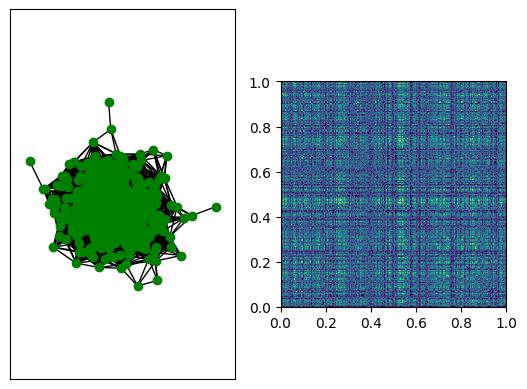

Estimated eps = 0.5755092624190713 for delta = 1


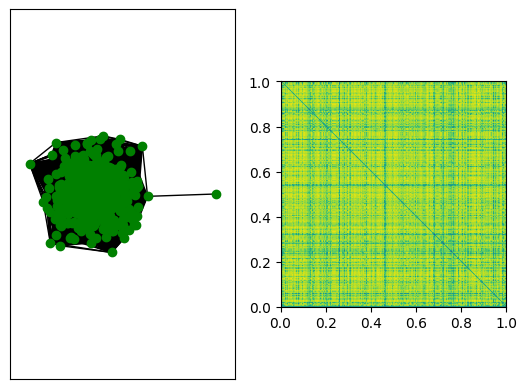

Estimated eps = 2.5037803714537845e-06 for delta = 5


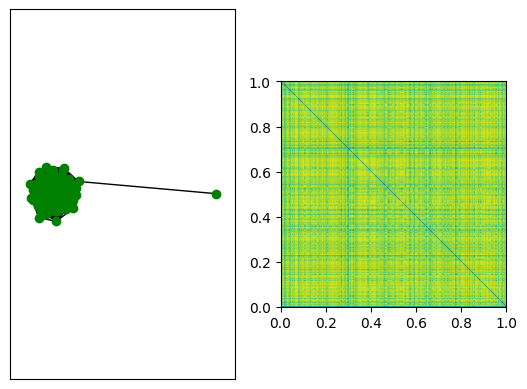

Estimated eps = 3.1689347865027125e-26 for delta = 10


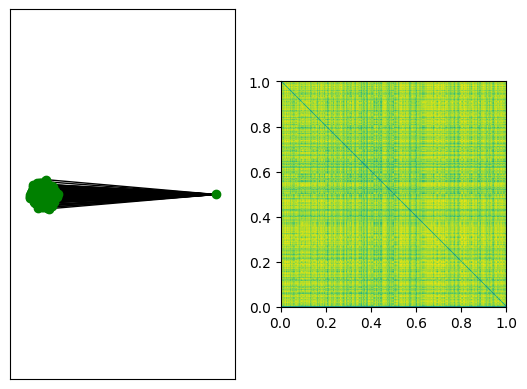

Estimated eps = 3.715956459738814e-94 for delta = 20


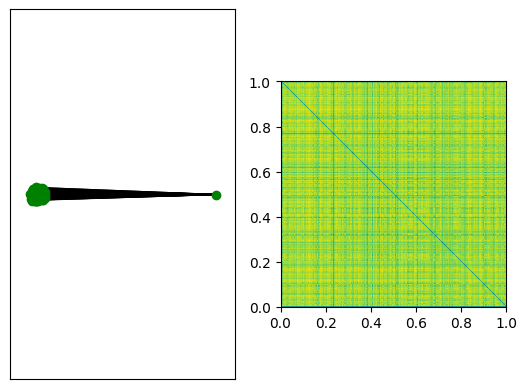

Estimated eps = 4.358014692690328e-213 for delta = 30


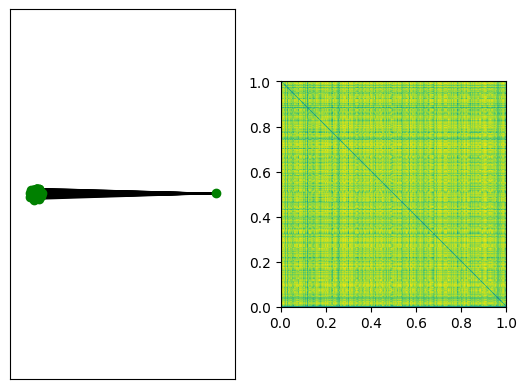

Estimated eps = 0.0 for delta = 40


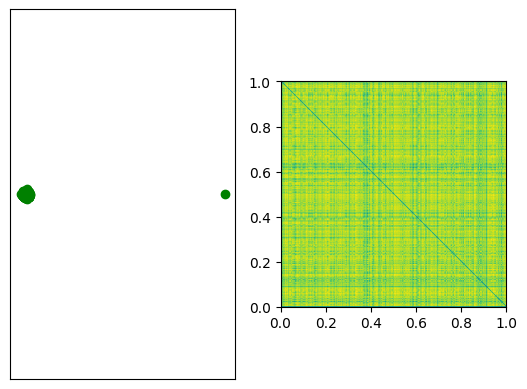

Estimated eps = 0.0 for delta = 50


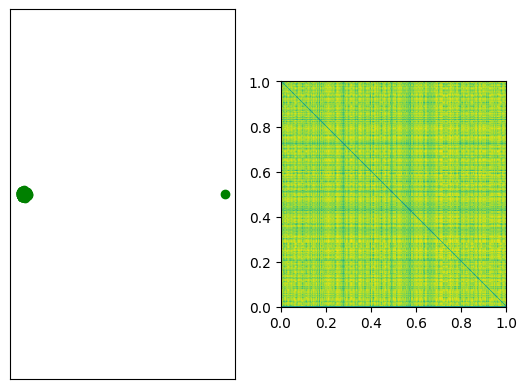

In [8]:
for delta in [0, 1, 5, 10, 20, 30, 40, 50]:
    X, Y = worst_case_blob(num_samples=600, delta=delta)
    W = build_similarity_graph(X, eps=0, k=0) # fully connencted graph

    cost_W = np.max(W) - W

    T = min_span_tree(cost_W)
    T = W[T]
    eps = np.min(T)

    print(f"Estimated eps = {eps} for delta = {delta}")
    W_with_eps = build_similarity_graph(X, eps = eps)
    plot_graph_matrix(X, Y, W_with_eps)

From the plots, we can confirm that our previous approach was correct. Indeed, the estimated values of $\epsilon$ are close to those obtained with the first approach, and once again, as delta increases, these values become numerically unstable. The conclusion on choice of $\epsilon$ therefore remains the same as before.

### Q1.3: Is it important to build a connected graph? Compare k-NN to $\epsilon$-graphs with respect to the difficulty of building a connected graph.

Per [Ulrike von Luxburg, 2007](https://arxiv.org/abs/0711.0189), it is important to build a graph that is connected, or at least has a only a small number of connected components and almost no isolated vertices. If the graph has more connected components than the number of clusters, spectral clustering would trivially return these components as clusters. Unless we are sure that connected components correspond to true clusters, this would imply that the algorithm does not learn and discover from the structure in the components and graphs data, yet it mirrors the graph topology we passed to it. 

We will write and run the code for visualizing the connectivity of both k-NN- and $\epsilon$-graphs for different $k$ and $\epsilon$ values.

==========Epsilon = 0.05==========

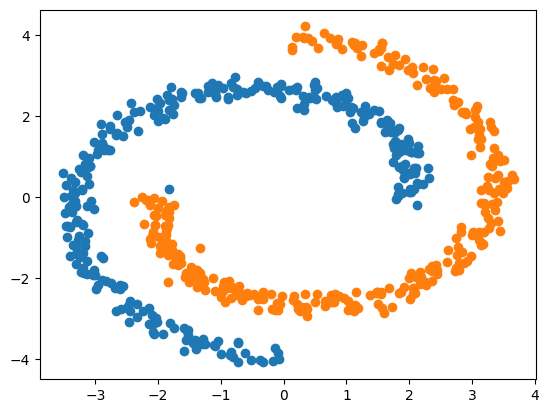

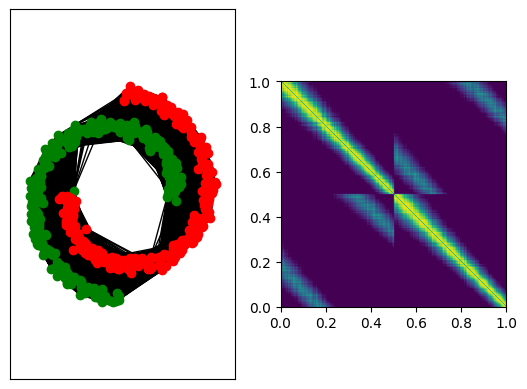

==========Epsilon = 0.1==========

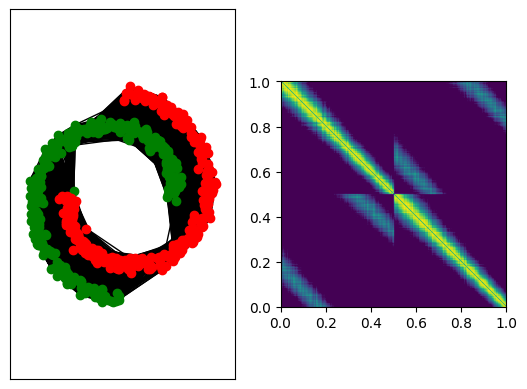

==========Epsilon = 0.2==========

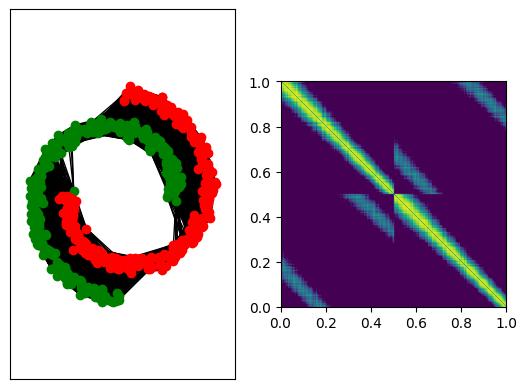

==========Epsilon = 0.3==========

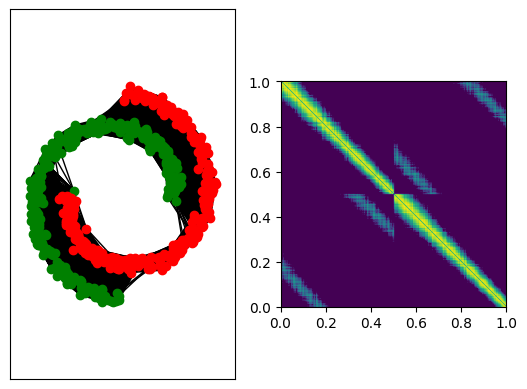

==========Epsilon = 0.4==========

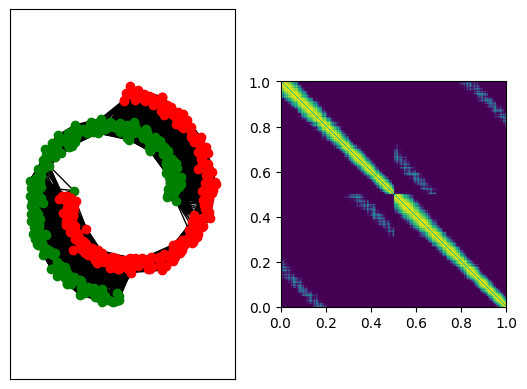

==========Epsilon = 0.8==========

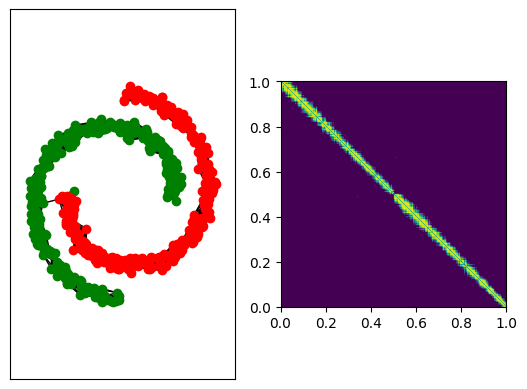

==========k = 3==========

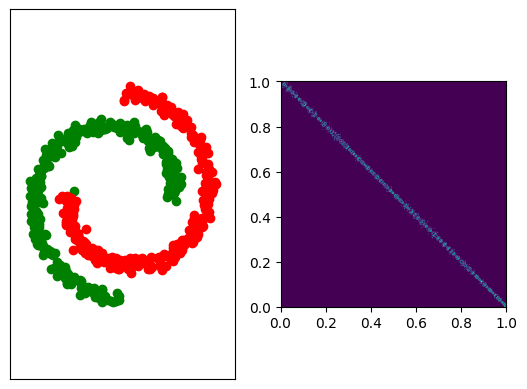

==========k = 5==========

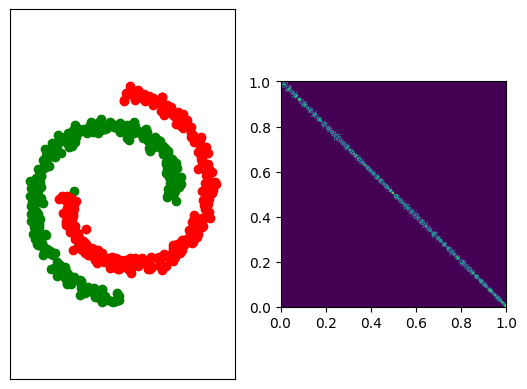

==========k = 10==========

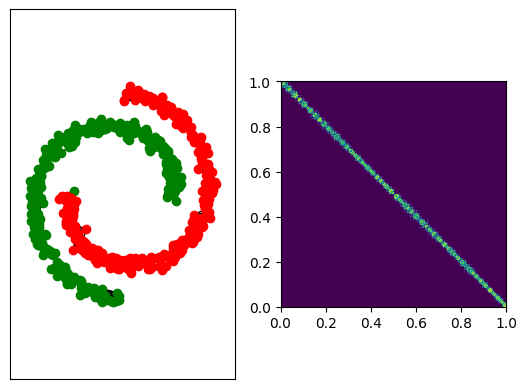

==========k = 20==========

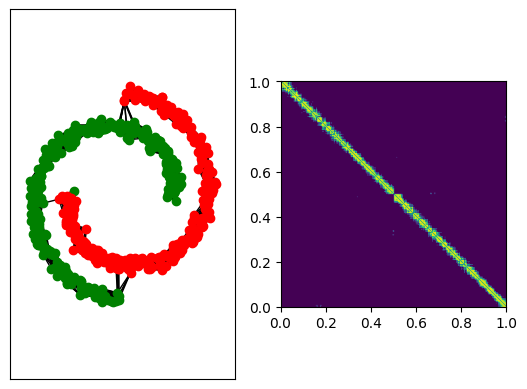

==========k = 50==========

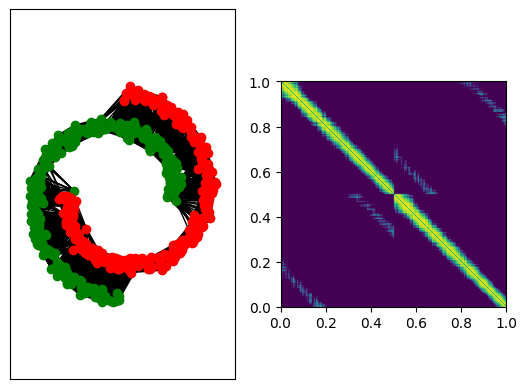

==========k = 100==========

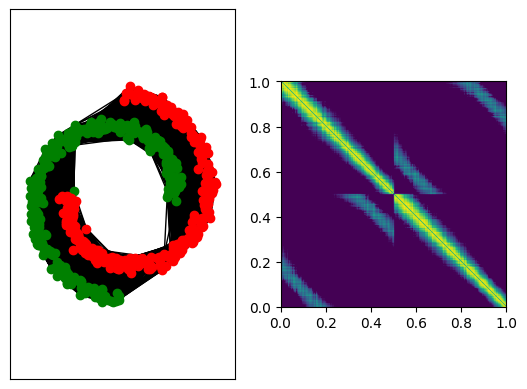

==========Epsilon = 0.05==========

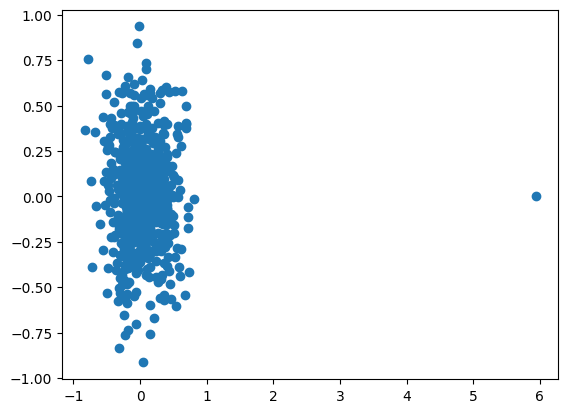

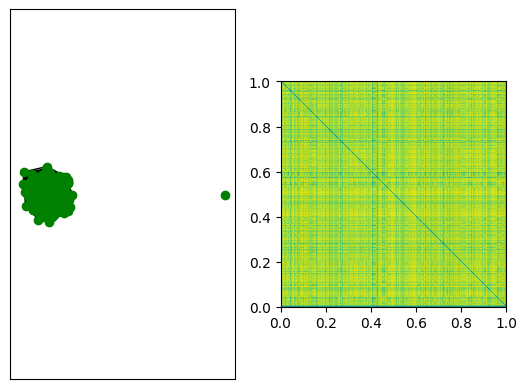

==========Epsilon = 0.1==========

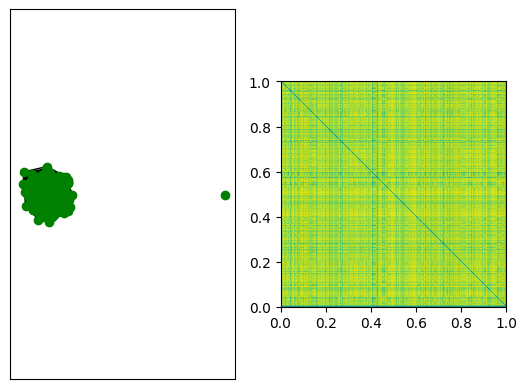

==========Epsilon = 0.2==========

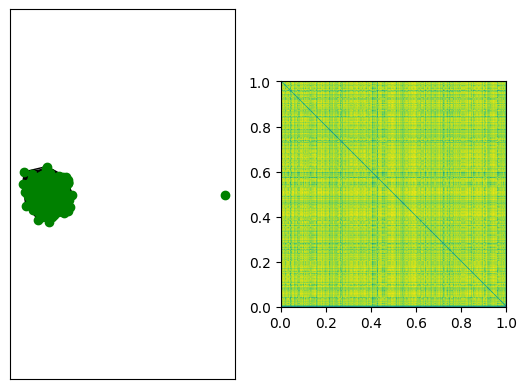

==========Epsilon = 0.3==========

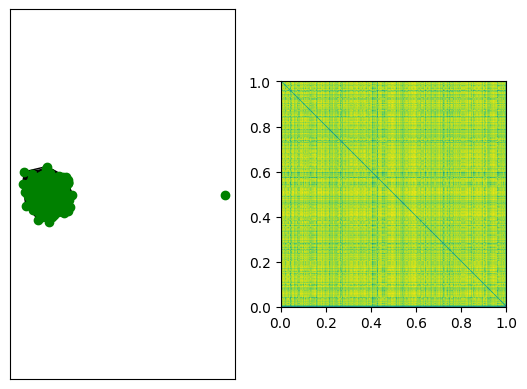

==========Epsilon = 0.4==========

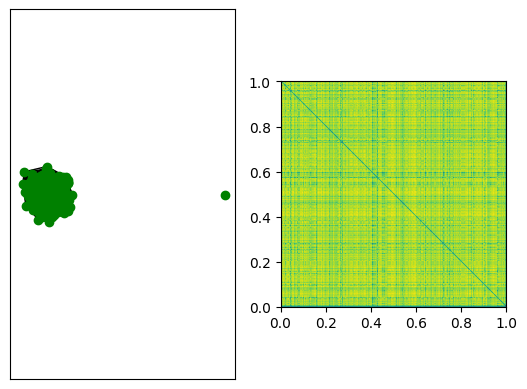

==========Epsilon = 0.8==========

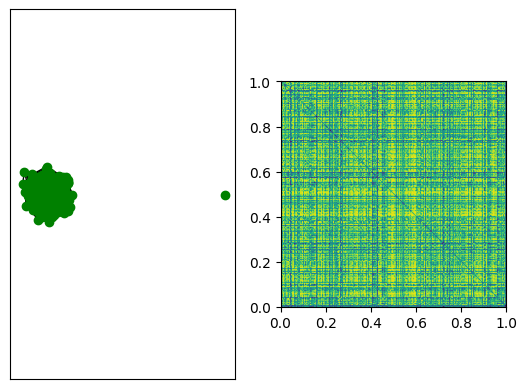

==========k = 3==========

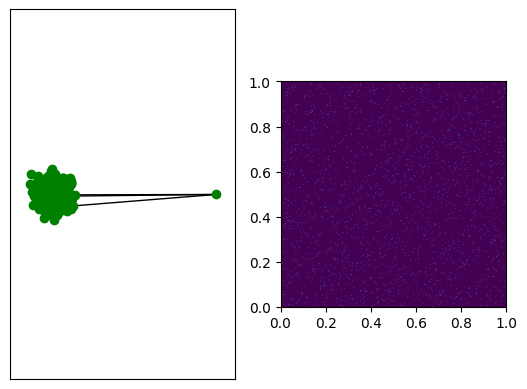

==========k = 5==========

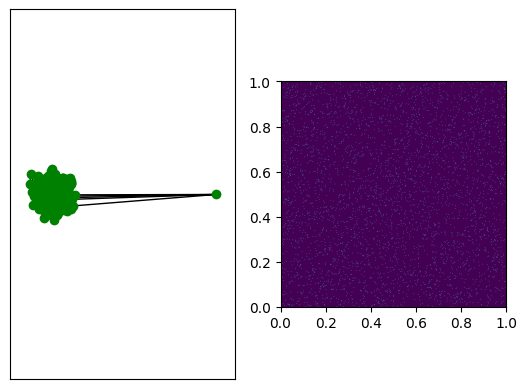

==========k = 10==========

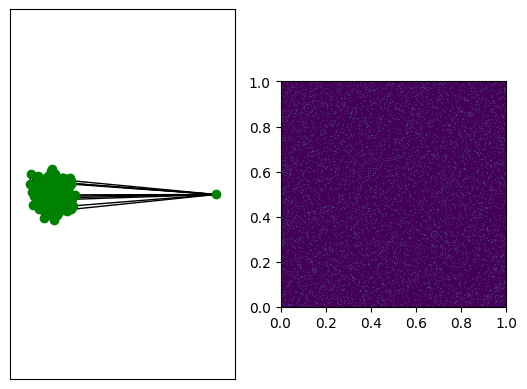

==========k = 20==========

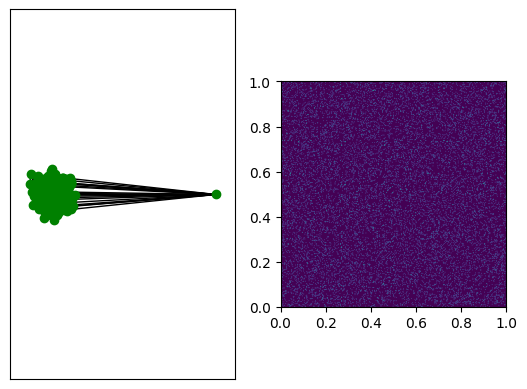

==========k = 50==========

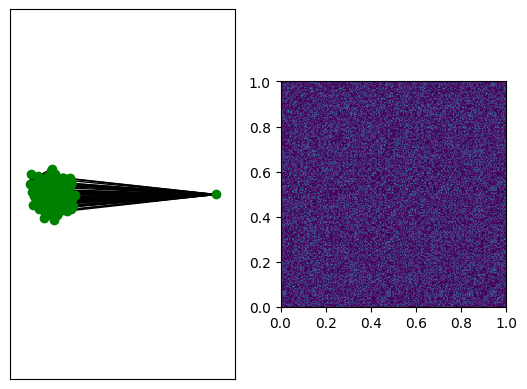

==========k = 100==========

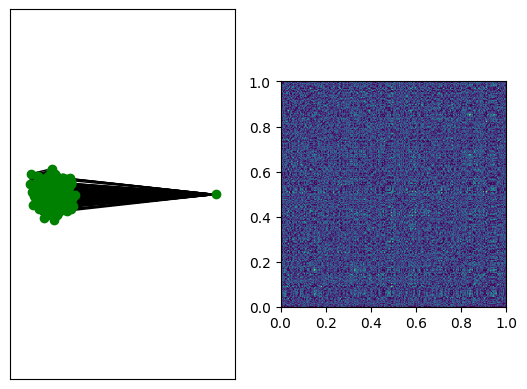

==========Epsilon = 0.05==========

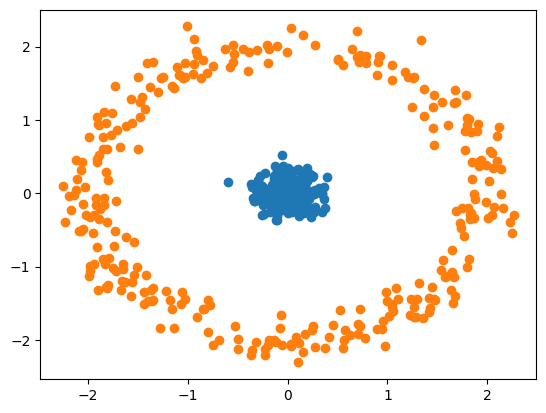

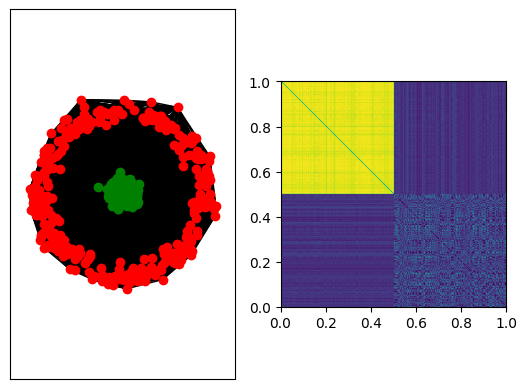

==========Epsilon = 0.1==========

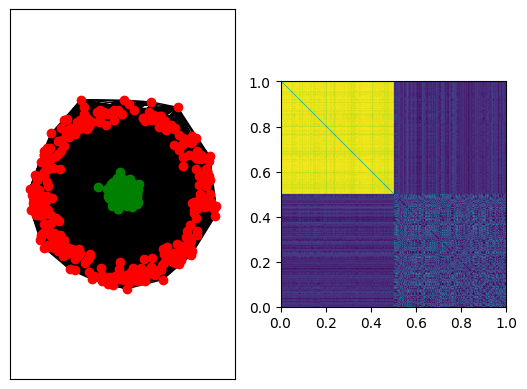

==========Epsilon = 0.2==========

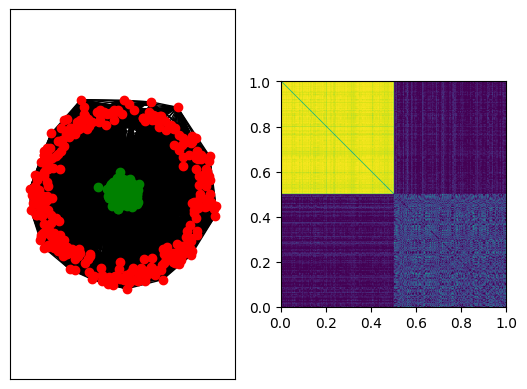

==========Epsilon = 0.3==========

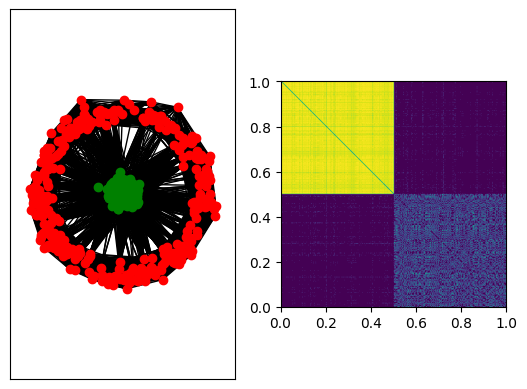

==========Epsilon = 0.4==========

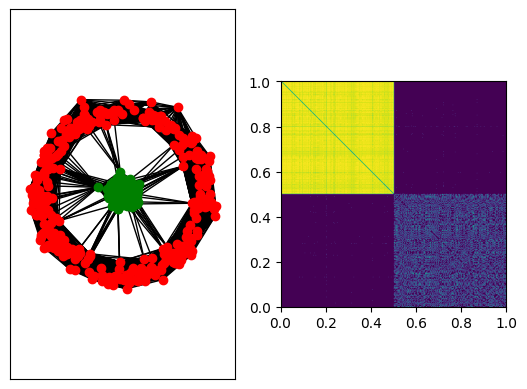

==========Epsilon = 0.8==========

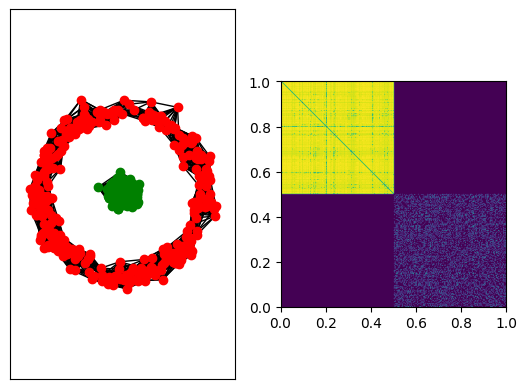

==========k = 3==========

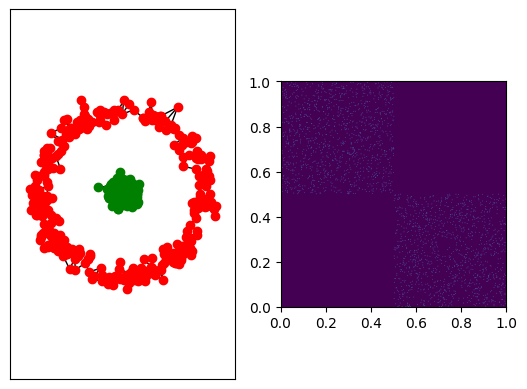

==========k = 5==========

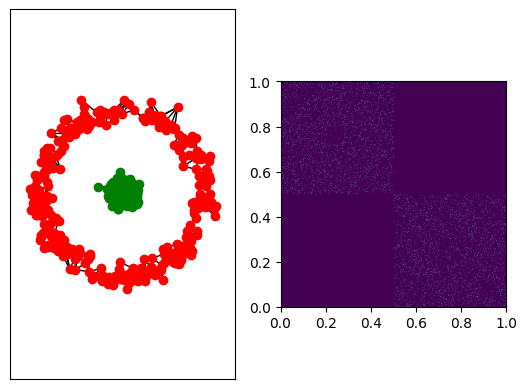

==========k = 10==========

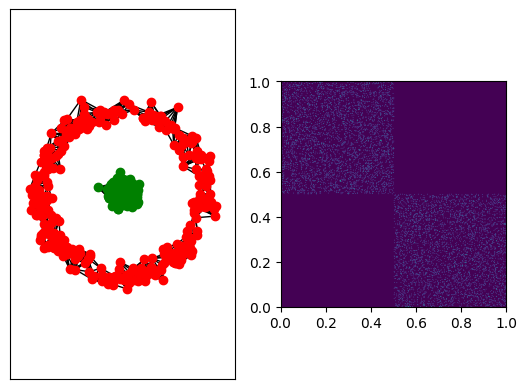

==========k = 20==========

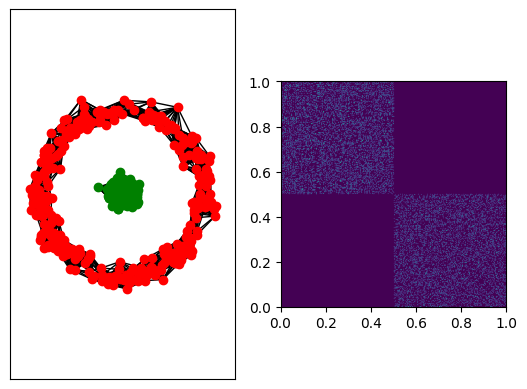

==========k = 50==========

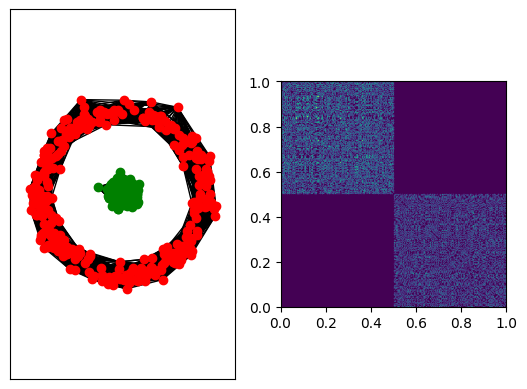

==========k = 100==========

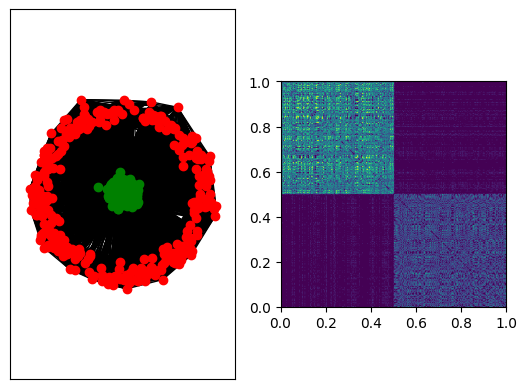

==========Epsilon = 0.05==========

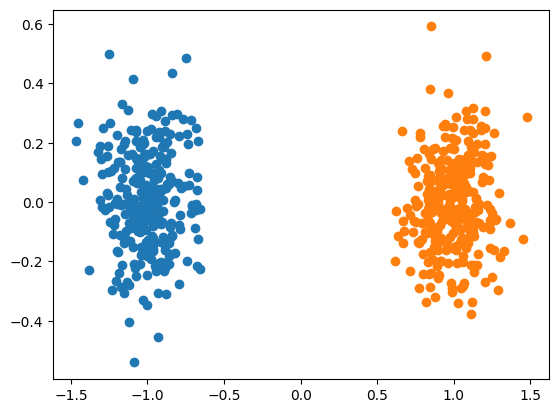

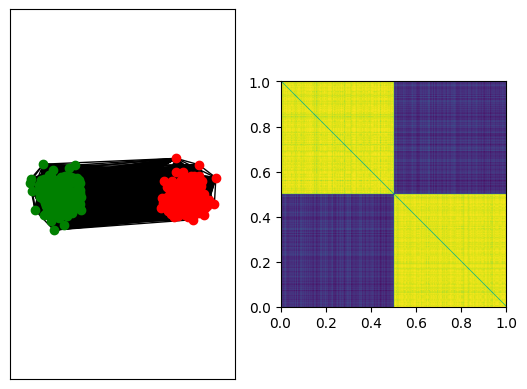

==========Epsilon = 0.1==========

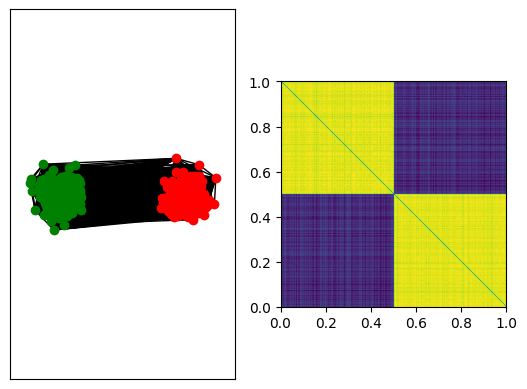

==========Epsilon = 0.2==========

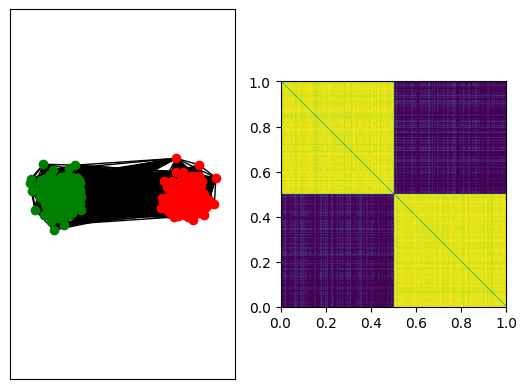

==========Epsilon = 0.3==========

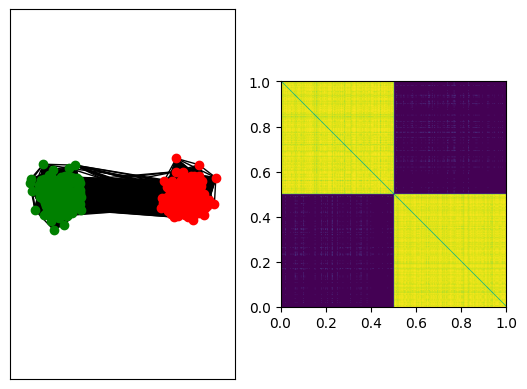

==========Epsilon = 0.4==========

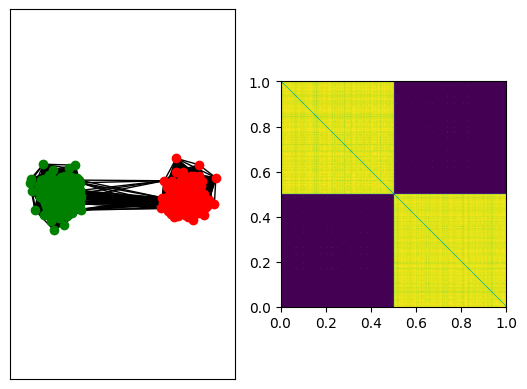

==========Epsilon = 0.8==========

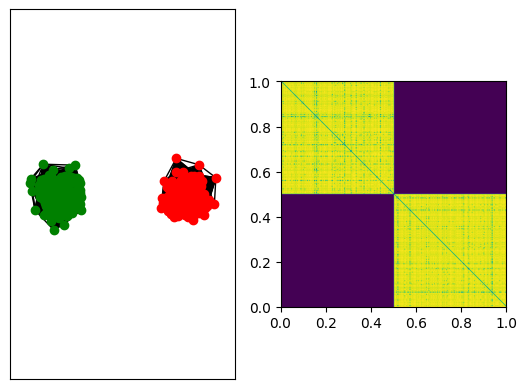

==========k = 3==========

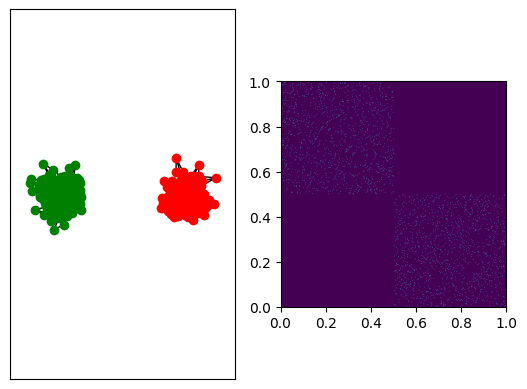

==========k = 5==========

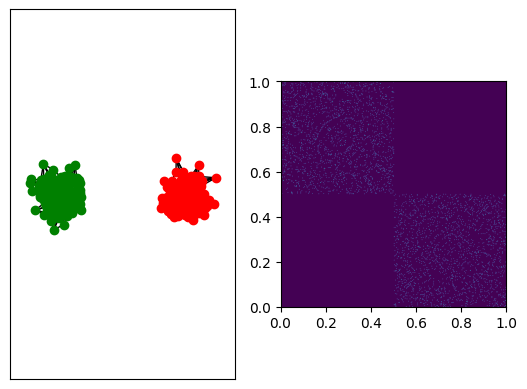

==========k = 10==========

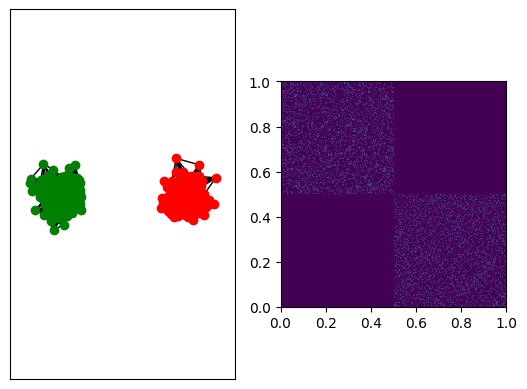

==========k = 20==========

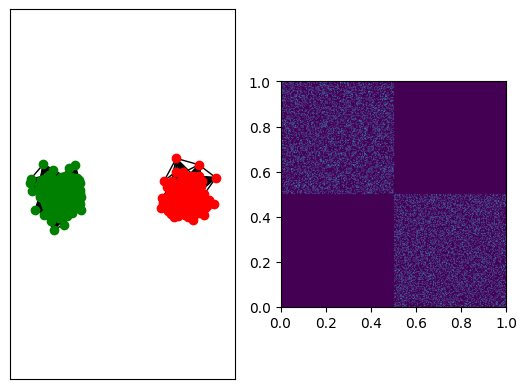

==========k = 50==========

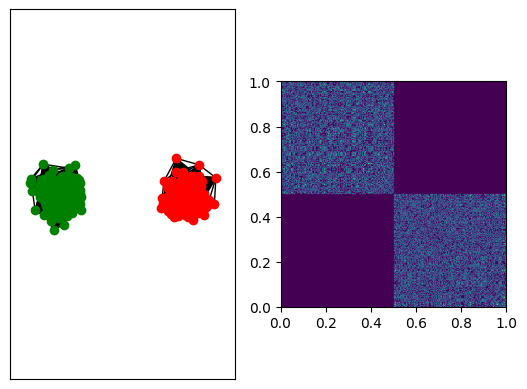

==========k = 100==========

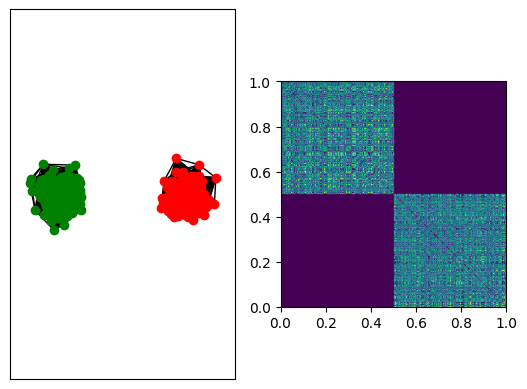

In [157]:
epsilons = [0.05, 0.1, 0.2, 0.3, 0.4, 0.8]
ks = [3, 5, 10, 20, 50, 100]

# for fn in [worst_case_blob]:  #  try also [worst_case_blob, point_and_circle, blobs]
for fn in [two_moons, worst_case_blob, point_and_circle, blobs]:  #  try also [worst_case_blob, point_and_circle, blobs]
# for fn in [blobs]:  #  try also [worst_case_blob, point_and_circle, blobs]
    X, Y = fn(num_samples=600)
    plot_clusters(X, Y, fignum=str(fn))
    
    for eps in epsilons:
        print("="*10, end="")
        print(f"Epsilon = {eps}", end="")
        print("="*10, end="")
        W = build_similarity_graph(X, eps = eps)
        plot_graph_matrix(X, Y, W)
    
    for k in ks:
        print("="*10, end="")
        print(f"k = {k}", end="")
        print("="*10, end="")
        W = build_similarity_graph(X, k=k)
        plot_graph_matrix(X, Y, W)

Observations:
- `two_moons` and `point_and_circle`: In both cases, we are dealing with well separated and dense clusters. In this setting, $\epsilon$-graphs produce connected graphs most of the time, except for the highest values of $\epsilon$ (e.g., >0.8). This is because the distances (both inter and intra) between samples are relatively small, so the similarity values are usually higher then the $\epsilon$ treshold. On the contrary, k-NN graphs are connected only when $k$ value is sufficiently high (e.g., 50 or 100). This is because the method tends to connect the samples within the same (dense) cluster, and when $k$ is small, the edges do not reach farther points (the ones in the other cluster). Therefore, we would need to increase the $k$ to make the graph connected.
- `worst_case_blob`: As discussed in the previous question, $\epsilon$-graphs would produce connected graphs only for (extremely) small values of $\epsilon$. Since `delta=5` by default (i.e., the distance between the outlier and closest sample to it is relatively large), we would require $epsilon \approx 3*10^{-6}$, thus, this method does not work well in this case. In contrast, k-NN approach guarantees that the outlier will be connected to $k$ other samples from the blob, so it will not stay isolated. Therefore, k-NN method is a better choice in this case.
- `blobs`: The results for this data are similar to the ones of `two_moons` and `point_and_circle`. We again see that $\epsilon$ succesfully builds the connected graph, while the k-NN graph, even with the highest tested value of $k=100$, remains disconnected. This happens because the clusters contain equal number of samples, and therefore, one would need $k>=300$ to connect samples between clusters.

Based on these observations, we can conclude that for graphs with dense regions and relatively small inter-distances, $\epsilon$-graphs can easily construct connected graphs. In contrast, when outliers are present, as in case of `worst_case_blob`, k-NN are significantly easier, and more appropriate to use. This comes from the ability of k-NN graphs to connect points on different scales of the space, which in this case corresponds to connecting the main dense blob to farly distanced outlier. However, when samples are well separated into dense clusters that are far away from each other, k-NN method may break the graph into several disconnected components (as in case of `two_moons` or `point_and_circle`).

In general (not limited to our data), I would say k-NN graphs are easier to tune and more interpretable for connectivity, whereas $\epsilon$-graphs, although sometimes can be more useful, are more sensitive to the choice of $\epsilon$ and can be difficult to tune appropriately.

### Q2.1: Build a graph starting from the data generated in `blobs`, and keep the graph connected. Use `spectral_clustering` to cluster the data. Motivate your choice on which eigenvectors to use and how you computed the clustering assignments from the eigenvectors. Now compute a similar clustering using the built-in k-means and compare the results.

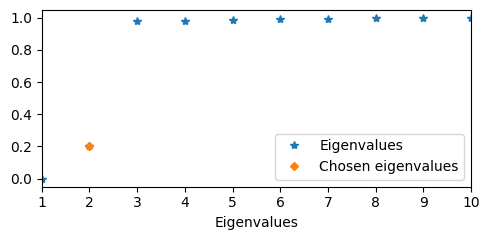

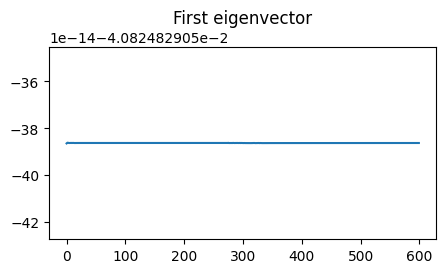

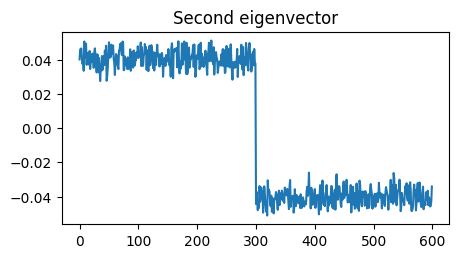

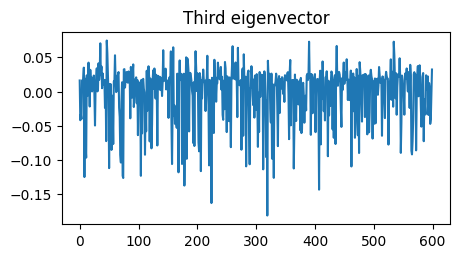

In [207]:
X, Y = blobs(num_samples=600)
eps = 0.1
chosen_eig_indices = [1]

W = build_similarity_graph(X, eps=eps)
L = build_laplacian(W, "rw")
_, eigenvalues, eigenvectors = spectral_clustering(L, num_classes=2, chosen_eig_indices=chosen_eig_indices)

plt.figure(figsize=(5, 2.5))
plt.plot(eigenvectors[:,0])
plt.title("First eigenvector")
plt.show()
plt.figure(figsize=(5, 2.5))
plt.title("Second eigenvector")
plt.plot(eigenvectors[:,1])
plt.show()
plt.figure(figsize=(5, 2.5))
plt.title("Third eigenvector")
plt.plot(eigenvectors[:,2])
plt.show()

As discussed in the previous question, $\epsilon$-graph more easily makes the `blobs` graph connected, so we choose to work with it for buildig the similarity graph. We also use the random-walk normalization of Laplacian.

We plotted the first 10 eigenvalues, as well as the first three eigenvectors. Since the graph is connected, the zero eigenvalue, which corresponds to the number of connected components, has a multiplicity of 1. However, from the plots, we observe that its corresponding eigenvector is constant. Moreover, as the third eigenvector appears noisy, we decide to focus only on the second eigenvector. This choice is also supported by the eigenvalues plot, where we clearly see a large gap between the second and third eigenvalues, indicating that the third eigenvector should not be included.

From the second eigenvector plot, we observe that there is a set of components that has negative values, and the set of components with positive values. These two sets correspond to two clusters, so we use only the second eigenvector for clustering. 

We will now plot clustering results and compute the accuracy score for both spectral clustering with thresholding and k-means.

Accuracy score spectral threshold: 1.0
Accuracy score kmeans: 1.0


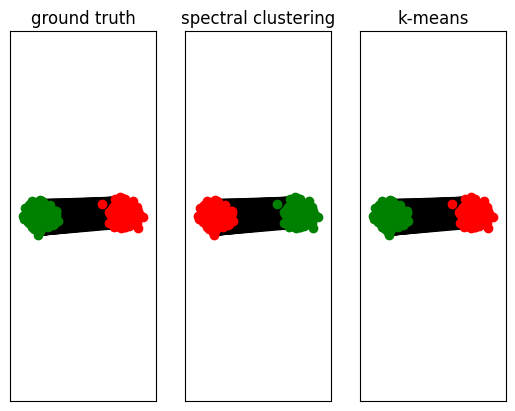

In [206]:
Y_rec_sc_threshold = (eigenvectors[:, 1] > 0).astype(int)
Y_rec_km = KMeans(n_clusters=2, random_state=42).fit_predict(X)

print("Accuracy score spectral threshold:", skm.adjusted_rand_score(Y, Y_rec_sc_threshold.ravel())) 
print("Accuracy score kmeans:", skm.adjusted_rand_score(Y, Y_rec_km.ravel())) 
plot_clustering_result(X, Y, W, Y_rec_sc_threshold, Y_rec_km)

For the thresholding method, we take the second eigenvector and compare its values to the threshold of 0, which separates the data into two sets with negative and positive values, as discussed above.

We observe that both methods work well, both visually, and metrically with 100% accuracy.

### Q2.2: Build a graph starting from the data generated in `blobs`, but this time make it so that the two components are separated. How do you choose which eigenvectors to use in this case? Motivate your answer.

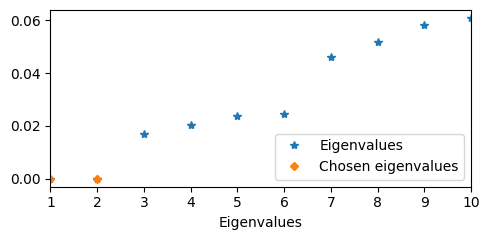

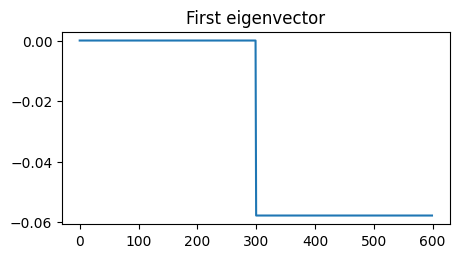

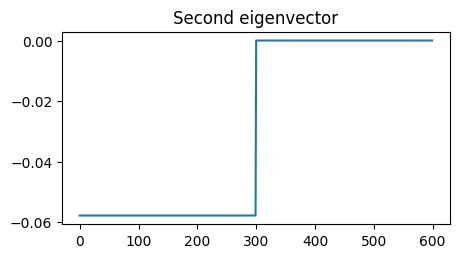

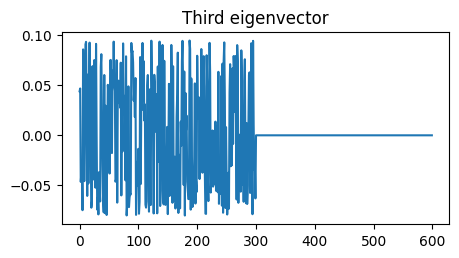

In [212]:
X, Y = blobs(num_samples=600)
k = 10
chosen_eig_indices = [0, 1]

W = build_similarity_graph(X, k=k)
L = build_laplacian(W, "rw")
Y_rec_sc, eigenvalues, eigenvectors = spectral_clustering(L, num_classes=2, chosen_eig_indices=chosen_eig_indices)

plt.figure(figsize=(5, 2.5))
plt.plot(eigenvectors[:,0])
plt.title("First eigenvector")
plt.show()
plt.figure(figsize=(5, 2.5))
plt.title("Second eigenvector")
plt.plot(eigenvectors[:,1])
plt.show()
plt.figure(figsize=(5, 2.5))
plt.title("Third eigenvector")
plt.plot(eigenvectors[:,2])
plt.show()

To build a graph with two separated components, we use k-NN graph with a small value of $k=10$, as this enforces connections only between nearby points. As  verified in Q1.3, the resulting graph is not connected for this choice of $k$.

We again plot the first 10 eigenvalues, as well as the first three eigenvectors. Since the graph now has two connected components, the zero eigenvalue has a multiplicity of 2 (i.e., equal to the number of connected components). This is confirmed by our plots, where both first and second eigenvector separate the data into two separate components (aformentioned discussion of components with positive and negative values). Therefore, we use only these two eigenvectors for clustering. As an additional observation, we would like to mention that there is again a large gap between the second and third eigenvector, so we intentionally skip the third one.

We again plot clustering results and compute the accuracy score for both spectral clustering with thresholding and k-means.

Accuracy score spectral threshold: 1.0
Accuracy score kmeans: 1.0


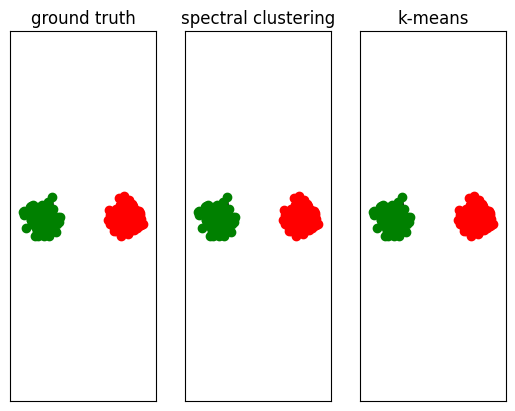

In [215]:
Y_rec_sc_threshold = (eigenvectors[:, 1] > np.median(eigenvectors[:, 1])).astype(int)
Y_rec_km = KMeans(n_clusters=2, random_state=42).fit_predict(X)

print("Accuracy score spectral threshold:", skm.adjusted_rand_score(Y, Y_rec_sc_threshold.ravel())) 
print("Accuracy score kmeans:", skm.adjusted_rand_score(Y, Y_rec_km.ravel())) 
plot_clustering_result(X, Y, W, Y_rec_sc_threshold, Y_rec_km)

Since the first two eigenvectors both separate the data into two components, either of them can be used for thresholding. We specifically choose the second eigenvector and compare its values to  their median. We could have equivalently used the first eigenvector, as it yields te same partition up to a sign change.

Again, we observe that both methods work well, both visually, and metrically, with 100% accuracy.

### Q2.3: In the function spectral_clustering, implement an automatic strategy to choose the eigenvectors to use for clustering, when chosen_eig_indices=None. Explain your strategy. Generate a dataset with 4 blobs and test your function. What happens when the variance of the blobs increase?

To automatically choose the eigenvectors for clustering when chosen_eig_indices=None, we can follow the eigengap heuristic. We first compute and sort the eigenvalues and eigenvectors of Laplacian, as before. Then, given the eigenvalues $\lambda_0 \le \lambda_1 \le ... \lambda_{n-1}$, we search for index $k$ among smallest eigenvalues such that the gap $|\lambda_k - \lambda_{k+1}|$ is relatively high. We use the random-walk normalized Laplacian for this matter. The intution is  to choose eigenvectors associated with small eigenvalues, which capture most meaningful inormation and therefore can be used to correctly cluster the properties of the graph, while finding a large eigengap that indicates a transition from this informative region to the noisy one.

In our implementation, we first compute the gaps between the first 10 consecutive (and sorted) eigenvalues. We do the slicing because higher eigenvalues are less meaningful for clustering, yet they can exhibit large gaps that would falsely be selected, which we want to avoid. We then find the maximum gap and extract the index $k$ of the eigenvalue right before that gap.

The problem with this approach is that, even when the "correct" gap is visually evident by human, the method still may select the largest gap among all and therefore misplace the desired gap. Alternative approach would be to iterate through the gaps and, once the gap exceeds an arbitrary threshold, stop and extract the index $k$ in the same manner. This also comes with its own issue such that, (especially when increasing the var), it becomes unclear what the threshold should be. One possibility would be to use the median of the gaps.

Finally, when we obtain the index $k$, we set the indices of chosen eigenvectors to range first $k+1$ eigenvectors.

==========var = 0.15==========

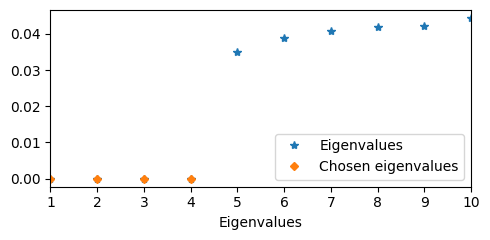

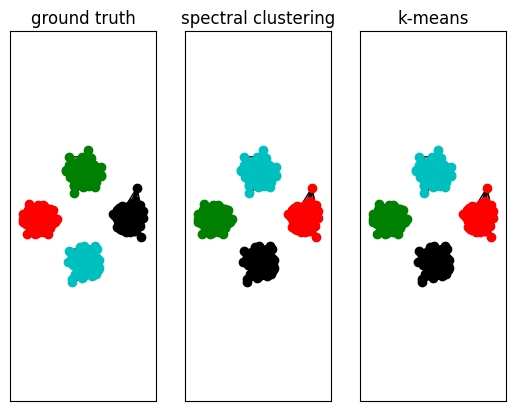

Accuracy score spectral clustering: 1.0
Accuracy score kmeans: 1.0
==========var = 0.3==========

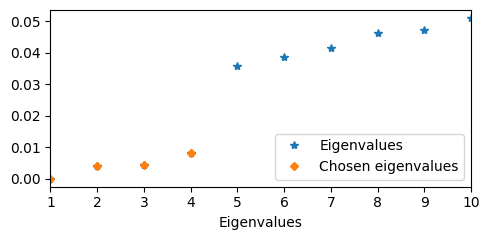

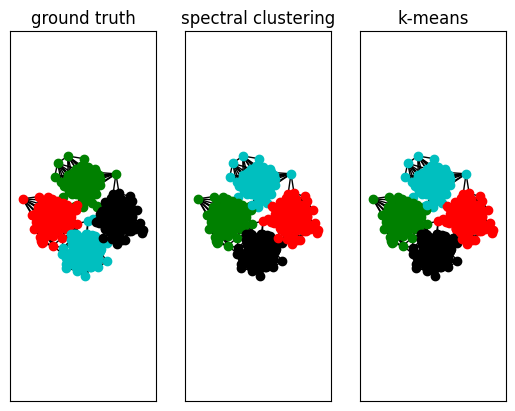

Accuracy score spectral clustering: 0.9601521448064452
Accuracy score kmeans: 0.9602378873949131
==========var = 0.5==========

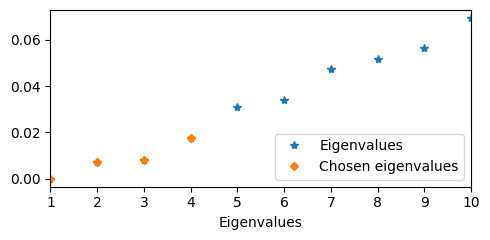

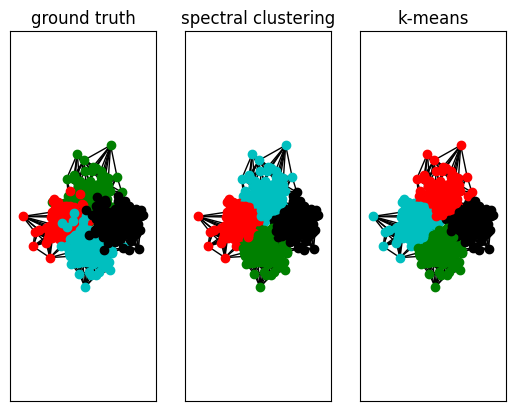

Accuracy score spectral clustering: 0.6927007045900988
Accuracy score kmeans: 0.6856366963518274
==========var = 0.7==========

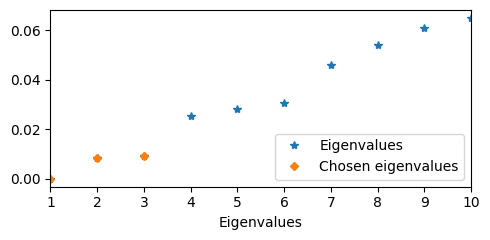

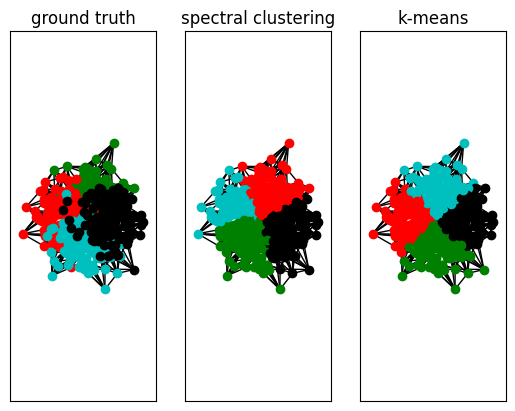

Accuracy score spectral clustering: 0.28816912766277436
Accuracy score kmeans: 0.36770237565146147


In [65]:
k = 10

for var in [0.15, 0.3, 0.5, 0.7]:
    print("="*10, end="")
    print(f"var = {var}", end="")
    print("="*10, end="")

    X, Y = blobs(num_samples=600, n_blobs=4, blob_var=var)
    W = build_similarity_graph(X, k=k)
    L = build_laplacian(W, "rw")
    Y_rec_sc, eigenvalues, eigenvectors = spectral_clustering(L, num_classes=4, chosen_eig_indices=None)
    Y_rec_km = KMeans(n_clusters=4, random_state=42).fit_predict(X)
    plot_clustering_result(X, Y, W, Y_rec_sc, Y_rec_km)

    print("Accuracy score spectral clustering:", skm.adjusted_rand_score(Y, Y_rec_sc.ravel())) 
    print("Accuracy score kmeans:", skm.adjusted_rand_score(Y, Y_rec_km.ravel()))

We observe 100% accuracy for small variance. In this case, the clusters are well separated and, as it can be seen from the eigenvalues plot, there are 4 eigenvalues close to zero, corresponding to (those) 4 clusters. After the 4th eigenvalue, there is a big and clear gap, which indicates that the first 4 eigenvectors should be used, exactly like our method does. Therefore, clustering is both stable and accurate in this case.

For `var=0.3`, the accuracy remains high. The first 4 eigenvalues are again small and close to zero, and there is still an evident large gap after the fourth eigenvalue. However, the clusters are now forming a single connected component, which is confirmed both visually and within the plot, where there is only one zero eigenvalue. This means that the clusters are now closer to each other and are starting to overlap.

As we increase the variance further, the clusters are overlapping even more, and the accuracy eventually drops. Looking at the eigenvalues plots, we observe several relatively large gaps with similar magnitudes. The plots show either a repeating pattern of pairs (or triples) of similar eigenvalues followed by a gap or a curved like distribution. Unlike in first two cases, the eigenvalues (and consequently the clusters) are no longer clearly separated. 

For `var=0.5`, the accuracy is reduced but remains decently high, and is still higher than one of k-means. However, for `var=0.7`, the accuracy drops significantly and below the k-means' one. Indeed, in this case, there are two large and comparable eigengaps, one after the 3rd eigenvalue, and another after the 6th. Our method selects the first gap and thus uses only 3 eigenvectors, which is insufficient to represent 4 clusters. To mitigate this, we could set the number of chosen eigenvectors to be at least the number of classes. 

In conclusion, as the variance increases, the inter-cluster similarities become closer to intra-cluster ones, which weakens the separation of the points. We believe this is why eigengap shifts to lower indices in the last example. Given said, we can conclude that our approach based on eigengap works well when the data contains well separated clusters (lower variances), but produces less reliable results when the cluster structure is ambiguous (higher variances).

### Q2.4: When you built the cluster assignment, did you use thresholding, k-means or both? Do you have any opinion on when to use each?

In Questions 2.1 and 2.2, we used both tresholding and k-means. The thresholding method could be used in these cases since there were only two clusters, for which it is sufficient to apply a threshold to the second eigenvector. As we have seen, this eigenvector separates the data into two clearly separated groups (either by sign or value). In this setting, a simple scalar threshold can yield a binary partition and correctly distinguish the clusters. Both methods here produced the same results.

However, when there are more than two clusters, thresholding heuristic becomes too simple and difficult to define. I assume that another problem is the use of a one-dimensional threshold for multi-dimensional clusters. For this reason, we did not use it in Question 2.3, where there were four clusters, and instead opted for k-means. K-means is a better choice in this case, as it naturally handles multiple clusters. This limitation of thresholding would be even more evident in image segmentation tasks, where cluster structures are more complex and cannot be this easily separated by simple one-dimensional thresholds.

In general, I would say that k-means is a more generalizable and robust approach, and should therefore be the preferred choice. Using threshold in Q2.1 and Q2.2 was, however, a nice way to understand and interpret the eigenvectors and clustering.

### Q2.5: Generate `two_moons` data and compare spectral clustering to k-means. Do you notice any difference? Taking into consideration the graph structure, can you explain them?

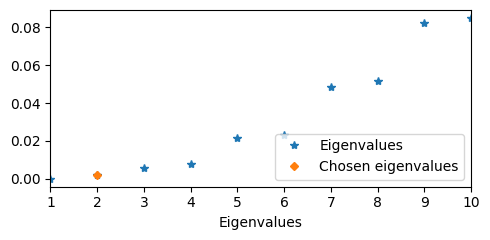

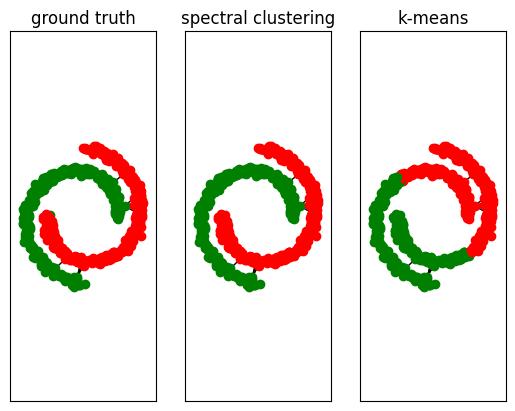

Accuracy score spectral clustering: 0.99333331487675
Accuracy score kmeans: -0.0015717591994502897


In [76]:
X, Y = two_moons(num_samples=600)
eps = 0.7
chosen_eig_indices = [1] # the same as in Q2.1

W = build_similarity_graph(X, eps=eps)
L = build_laplacian(W, "rw")
Y_rec_sc, eigenvalues, eigenvectors = spectral_clustering(L, num_classes=2, chosen_eig_indices=chosen_eig_indices)
Y_rec_km = KMeans(n_clusters=2, random_state=42).fit_predict(X)
plot_clustering_result(X, Y, W, Y_rec_sc, Y_rec_km)

print("Accuracy score spectral clustering:", skm.adjusted_rand_score(Y, Y_rec_sc.ravel())) 
print("Accuracy score kmeans:", skm.adjusted_rand_score(Y, Y_rec_km.ravel()))

We can verify both visually and numerically that spectral clustering performs much better. It achieves nearly perfect accuracy, while k-means score is near zero, which corresponds to random-like clustering.

This is because spectral clustering does not make strong assumptions on the form of the clusters. In contrast, k-means assumes and produces clusters that form convex sets, and therefore fails on non-convex data such as `two_moons`. This explains why spectral clustering, unlike k-means, can correctly cluster this type of data, which is called intertwined spirals.

Moreover, we can say that spectral clustering looks for connectivity, while k-means looks for compactness. For `two_moons`, we should aim for a connectivity, and therefore use spectral clustering over k-means.

### Q2.6: Generate `point_and_circle` data and compare spectral clustering using the normal Laplacian and the random-walk regularized Laplacian. Do you notice any difference? Taking into consideration the graph structure, can you explain them?

We will plot and compare spectral clustering results using both normal and random-walk regularized Laplacian, for different values of $\epsilon$.

==========Unnormalized Laplacian with eps=0.05==========

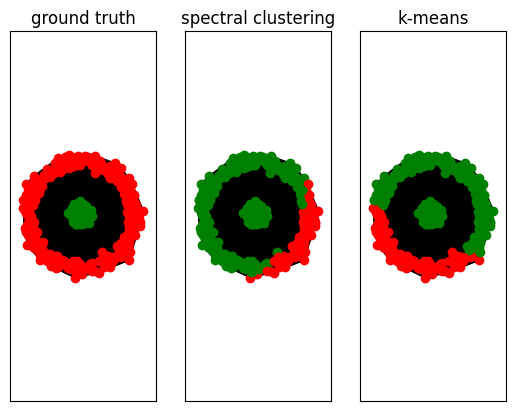

Accuracy score spectral clustering: 0.06517946284823523
Accuracy score kmeans: 0.12874125014037208
==========Random-walk Laplacian with eps=0.05==========

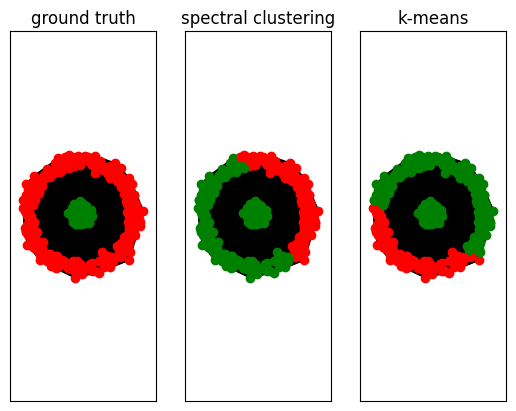

Accuracy score spectral clustering: 0.19267487819096876
Accuracy score kmeans: 0.12874125014037208
==========Unnormalized Laplacian with eps=0.15==========

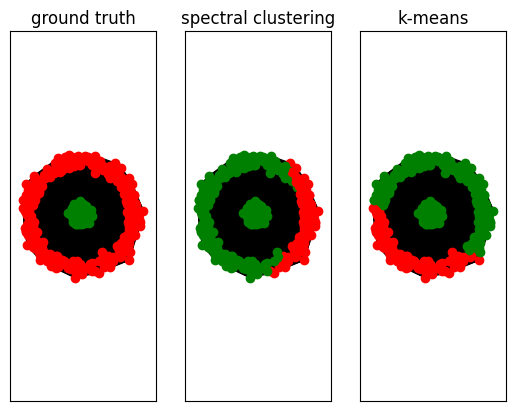

Accuracy score spectral clustering: 0.09325836622154944
Accuracy score kmeans: 0.12874125014037208
==========Random-walk Laplacian with eps=0.15==========

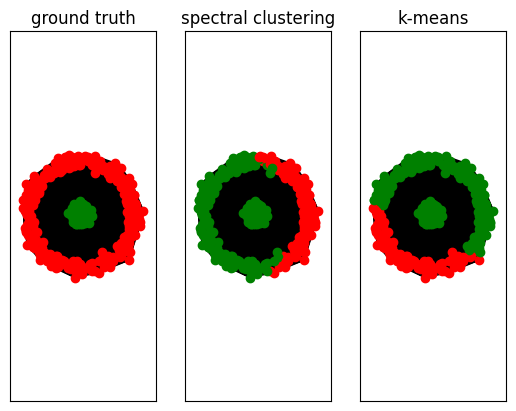

Accuracy score spectral clustering: 0.16447396519670582
Accuracy score kmeans: 0.12874125014037208
==========Unnormalized Laplacian with eps=0.2==========

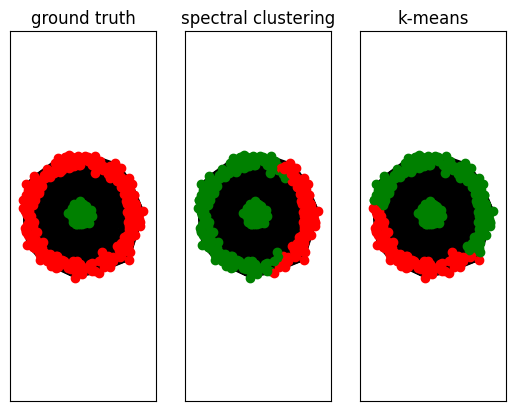

Accuracy score spectral clustering: 0.11476589962228183
Accuracy score kmeans: 0.12874125014037208
==========Random-walk Laplacian with eps=0.2==========

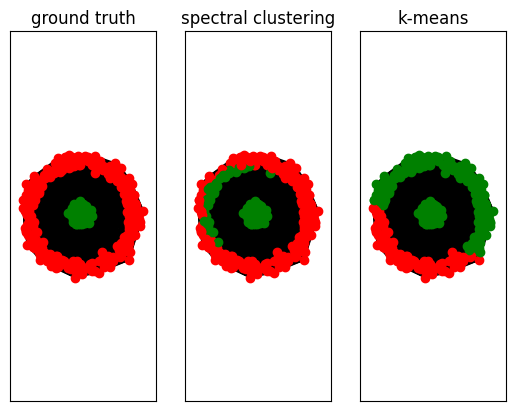

Accuracy score spectral clustering: 0.705120315919586
Accuracy score kmeans: 0.12874125014037208
==========Unnormalized Laplacian with eps=0.25==========

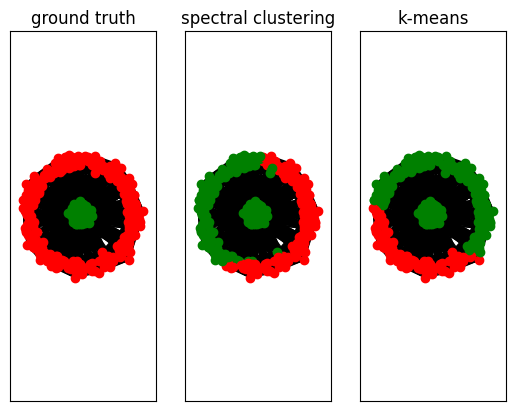

Accuracy score spectral clustering: 0.27996347168746527
Accuracy score kmeans: 0.12874125014037208
==========Random-walk Laplacian with eps=0.25==========

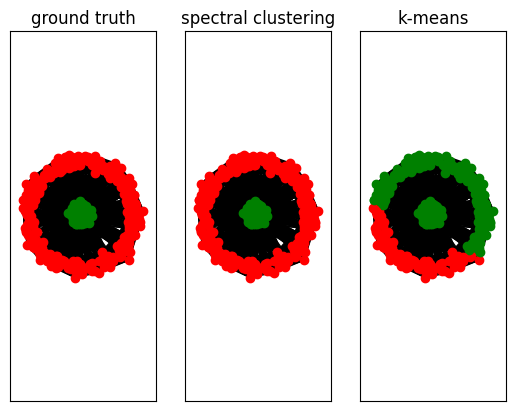

Accuracy score spectral clustering: 1.0
Accuracy score kmeans: 0.12874125014037208
==========Unnormalized Laplacian with eps=0.4==========

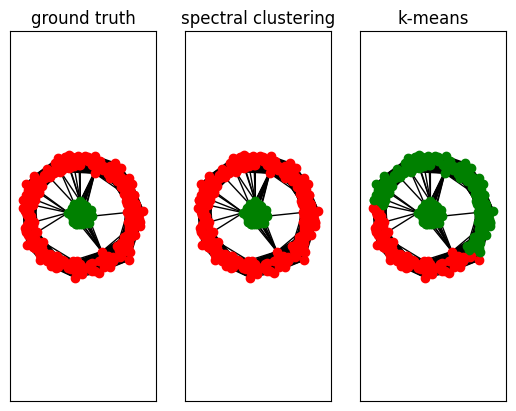

Accuracy score spectral clustering: 1.0
Accuracy score kmeans: 0.12874125014037208
==========Random-walk Laplacian with eps=0.4==========

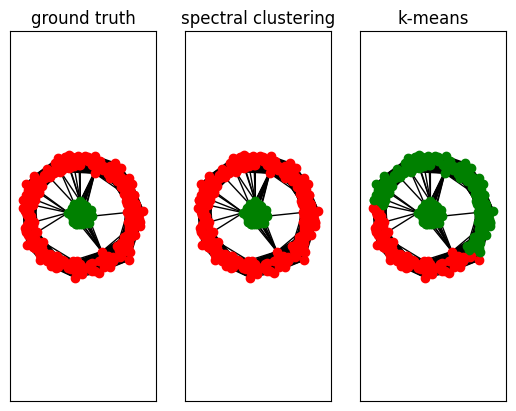

Accuracy score spectral clustering: 1.0
Accuracy score kmeans: 0.12874125014037208
==========Unnormalized Laplacian with eps=0.8==========

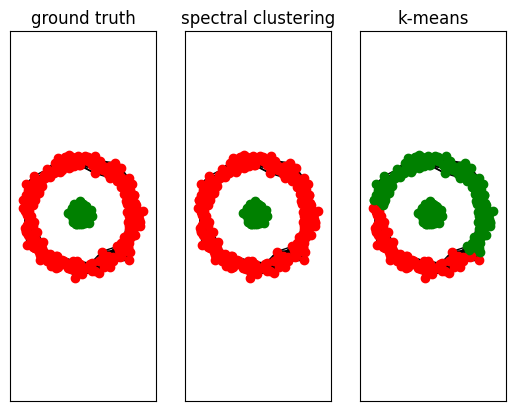

Accuracy score spectral clustering: 1.0
Accuracy score kmeans: 0.12874125014037208
==========Random-walk Laplacian with eps=0.8==========

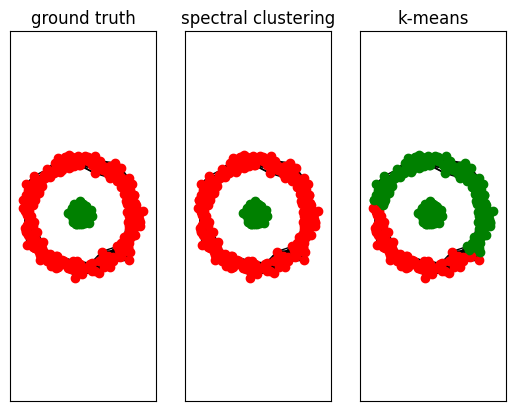

Accuracy score spectral clustering: 1.0
Accuracy score kmeans: 0.12874125014037208


In [124]:
X, Y = point_and_circle(num_samples=600)
chosen_eig_indices = [1] # the same as in Q2.1
for eps in [0.05, 0.15, 0.2, 0.25, 0.4, 0.8]:
    W = build_similarity_graph(X, eps=eps)

    # unnormalized laplacian
    print("="*10, end="")
    print(f"Unnormalized Laplacian with eps={eps}", end="")
    print("="*10, end="")
    L = build_laplacian(W, "unn")
    Y_rec_sc, eigenvalues, eigenvectors = spectral_clustering(L, num_classes=2, chosen_eig_indices=chosen_eig_indices)
    Y_rec_km = KMeans(n_clusters=2, random_state=42).fit_predict(X)
    plot_clustering_result(X, Y, W, Y_rec_sc, Y_rec_km)

    print("Accuracy score unnormalized:", skm.adjusted_rand_score(Y, Y_rec_sc.ravel())) 

    # rw normalization
    print("="*10, end="")
    print(f"Random-walk Laplacian with eps={eps}", end="")
    print("="*10, end="")
    L = build_laplacian(W, "rw")
    Y_rec_sc, eigenvalues, eigenvectors = spectral_clustering(L, num_classes=2, chosen_eig_indices=chosen_eig_indices)
    Y_rec_km = KMeans(n_clusters=2, random_state=42).fit_predict(X)
    plot_clustering_result(X, Y, W, Y_rec_sc, Y_rec_km)

    print("Accuracy score random-walk:", skm.adjusted_rand_score(Y, Y_rec_sc.ravel())) 

From both the plots and the accuracy metrics, we observe that the random-walk (rw) normalization consistently achieves equal or better performance than the unnormalized Laplacian. The improvement of rw normalization over the unnormalized one is small for the smallest values of $\epsilon$, and largest for its intermediate values of $\epsilon=0.2$ and $\epsilon=0.25$. For highest value of $\epsilon$, both approaches yield perfect accuracy score.

We can explain this behavior by the minimization objectives and graph structure. The unnormalized Laplacian corresponds to minimizing the RatioCut, while rw normalized Laplacian corresponds to NCut minimization. Both RatioCut and NCut aim to minimize the cut between clusters, but they do so in a different way. In particular, RatioCut normalizes the cut size by the number of vertices in clusters (i.e., wants to maximize this number), whereas NCut normalizes the cut size by the cluster volume (i.e., wants to maximize the volume).

Now, in case of `point_and_circle` data, we can see that the inner circle is compact, with low dispersion of points, while the ring (outer circle) has curved geometry and empty interior. For small and intermediate values of $\epsilon$, the inner circle has relatively uniform and high node degrees, due to the small distances between further points combined with small similarity threshold. In contrast, the ring nodes, although connected to their nearby neighbors, have weaker overall connectivity, mainly because they are more sparsely distributed.

We now go back to cuts. As described, since NCut normalizes by the volume, it avoids separating  regions with small volume (i.e., total degrees), because the denominator term would be small and would therefore increase the overall cut value. In our case, the region with smaller volume corresponds to the ring. Consequently, NCut, and thus rw-normalized Laplacian, as shown in plots, avoids cutting the ring, and instead prefers to cut between the ring and circle. In contrast, RatioCut and the unnormalized Laplacian, see the ring as a cheap cut, and since they do not take the volume (and also the inter-cluster similarity) into account, they can split the data within it. Based on these observations, we can conclude that rw normalization is a more robust approach when there is a region with lower and weaker connectivity, which explains its improved performance over unnormalized Laplacian for intermediate values of $\epsilon$. 

As a final note, we want to explain the results for other values of $\epsilon$. For its smallest values, the graphs are close to fully connected, so both methods struggle to find the information that would separate the clusters. However, because of the reasons explained above, rw unnormalized Laplacian still yields higher accuracy. In case of highest values, clusters in graphs are clearly separated, so both approaches have result in perfect accuracy.

### Q2.7: Using the function parameter_sensitivity, comment on the stability of spectral clustering when varying $\epsilon$ or k. 

zero eigen 38
zero eigen 3
zero eigen 2
zero eigen 2
zero eigen 2
zero eigen 2
zero eigen 2
zero eigen 2
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 1
zero eigen 2
zero eigen 2
zero eigen 2
zero eigen 0


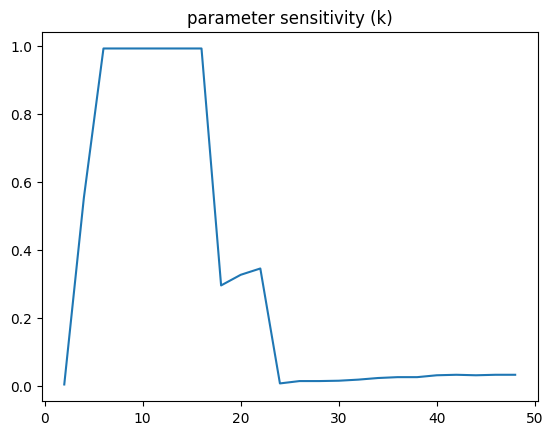

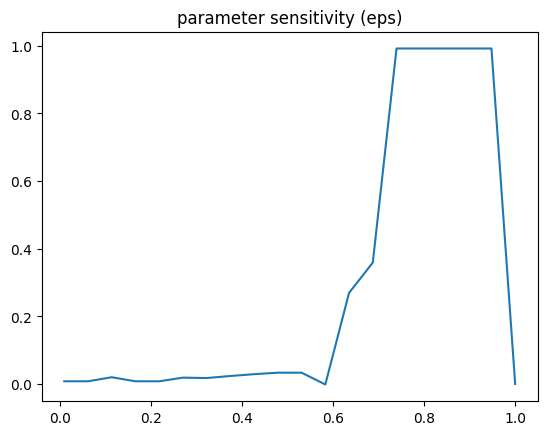

In [ ]:
parameter_sensitivity()
# ignore the prints below

From the plot we see that, depending on the choice of $\epsilon$ and $k$, we can achieve both perfect (100%) and (near-) zero accuracy on clustering. We can also notice that clustering (for `two_moons`) is successfull when $\epsilon$ is large or $k$ is small, or, in other words, when there are few and weak connections between the two clusters. This is shown by locally stable regions, that are, however, narrow. Moreover, even a small parameter change can lead to a large performance difference. For instance, increasing $\epsilon$ from 0.63 to 0.68 can reduce the inter-cluster connections and therefore increase the accuracy from near zero to perfect accuracy. Similarly, increasing $k$ from 14 to 16 increases the inter-cluster connectivity, which leads to a sharp drop in accuracy from ~100% to ~30%. Based on these observations, we can conclude that spectral clustering is both unstable and sensitive to the choice of $\epsilon$ and $k$.

### Q2.8: If we did not have access to "true" labels, how could we evaluate the clustering result (or what should we not use as evaluation)?

So far, we evaluated our results using both visual assesment and accuracy scores. If we did not have access to true labels, we would no longer be able to use accuracy, but visual inspection could still be beneficial to qualitatively understand the clustering results and factors that led to them. However, visual assesment is feasible mainly in low dimensional space, which means that for better generality, we need to use quantitative metrics, particularly, the unsupervised ones. These metrics provide the scores for clustering based on the data and cluster structure. We will now propose some of them.

One such metric is modularity. Modularity measures the number of edges that lie within a cluster compared to the expected number of edges of a random graph with the same degree distribution. It is based on both inter- and intra-cluster similarity and given by the following formula:

$$Q = \sum_{c=1}^{n_c} \left[\frac{l_c}{m} - \left(\frac{d_c}{2m}\right)^2\right].$$

Here, $m = |E|$ is the total number of edges, $n_c$ is the number of clusters, $l_c$ is the number of edges within the cluster $c$, and $d_c$ is the sum of the degrees of the nodes that belong to cluster $c$. The output range of modularity is $[-1, 1]$, with higher values indicating better clustering structure.

The above formulation can be rewritten as follows:
$$
Q = \frac{1}{2m} \sum_{i,j} \left( W_{ij} - \frac{d_i d_j}{2m} \right) \delta(C(i), C(j)),
$$
where $m = |E|$ is the total number of edges, $d_i$ is the degree of node $i$, and $\delta(C(i), C(j))=1$ if nodes $i$ and $j$ belong to the same cluster, otherwise 0.

Another validation metric that we could use is Davies-Bouldin index. It is defined as the average similarity between each cluster and its most similar one, where similarity is measured as the ratio between inter- and intra-cluster distances. Mathematically, this is written as follows:

$$
DB = \frac{1}{K} \sum_{i=1}^{K} \max_{j \neq i} \frac{s_i + s_j}{d_{ij}}.
$$

Here, $K$ denotes the number of clusters, $s_i = \frac{1}{|C_i|} \sum_{x \in C_i} ||x - c_i||_2$ is the intra-cluster distance for cluster $i$, and $d_{ij} = ||c_i - c_j||_2$ is the inter-cluster distance between clusters $i$ and $j$, where $c_i = \frac{1}{|C_i|} \sum_{x \in C_i} x$ represents the centroid of cluster $i$. The lowest value of this metric is zero, with lower values indicating better clustering separations.



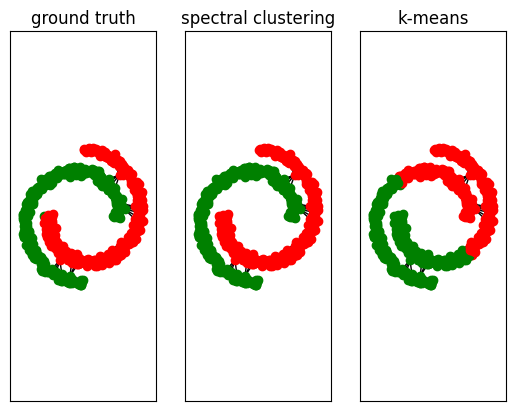

Modularity spectral clustering: 0.49832132134876206
Modularity kmeans: 0.46904345690839105


In [83]:
def modularity(W, Y):
    Q = 0.0

    d = W.sum(axis=1) 
    m = W.sum() / 2.0                 
    n = W.shape[0]

    for i in range(n):
        for j in range(n):
            if Y[i] == Y[j]:
                Q += W[i, j] - (d[i] * d[j]) / (2 * m)

    Q /= (2 * m)
    return Q

X, Y = two_moons(num_samples=600)
eps = 0.7
chosen_eig_indices = [1]

W = build_similarity_graph(X, eps=eps)
L = build_laplacian(W, "rw")
Y_rec_sc, eigenvalues, eigenvectors = spectral_clustering(L, num_classes=2, chosen_eig_indices=chosen_eig_indices, plot_eig=False)
Y_rec_km = KMeans(n_clusters=2, random_state=42).fit_predict(X)
plot_clustering_result(X, Y, W, Y_rec_sc, Y_rec_km)

modularity_sc = modularity(W, Y_rec_sc.ravel())
modularity_km = modularity(W, Y_rec_km.ravel())
assert (modularity_sc > modularity_km), "Spectral clustering should have higher modularity in this case"
print("Modularity spectral clustering:", modularity_sc) 
print("Modularity kmeans:", modularity_km)

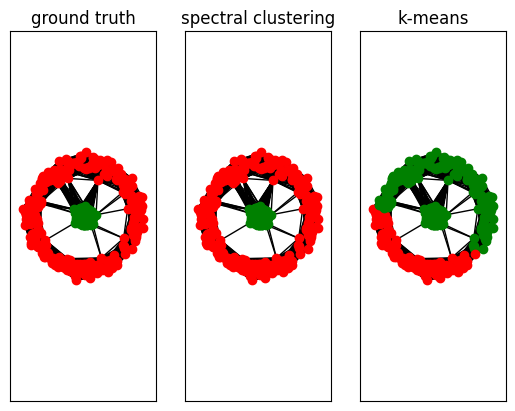

Modularity spectral clustering: 0.24919424251790703
Modularity kmeans: 0.11940136926694139


In [84]:
X, Y = point_and_circle(num_samples=600)
eps = 0.4
chosen_eig_indices = [1]

W = build_similarity_graph(X, eps=eps)
L = build_laplacian(W, "rw")
Y_rec_sc, eigenvalues, eigenvectors = spectral_clustering(L, num_classes=2, chosen_eig_indices=chosen_eig_indices, plot_eig=False)
Y_rec_km = KMeans(n_clusters=2, random_state=42).fit_predict(X)
plot_clustering_result(X, Y, W, Y_rec_sc, Y_rec_km)

modularity_sc = modularity(W, Y_rec_sc.ravel())
modularity_km = modularity(W, Y_rec_km.ravel())
assert (modularity_sc > modularity_km), "Spectral clustering should have higher modularity in this case"
print("Modularity spectral clustering:", modularity_sc) 
print("Modularity kmeans:", modularity_km)

We wrote a simple validation of the modularity. The results are consistent with the visual assesment, with spectral clustering achieving higher score. 

### Q3.1: Complete all the code necessary, and cluster the `four_elements` and `fruit_salad` images in the data folder and include here some images of the clustering.  Explain your design choices in the overall pipeline (e.g. which graph, which pre-processing...) and how you think they impact the results you are seeing. Report also at least one failure mode for the algorithm.

Our design choices are as follows:
- We first pre-process the images using min-max normalization to scale pixel values for better similarity graph construction. 
- We use a k-NN graph, as it is easier to tune for connectivity than $\epsilon$-graphs. The value of $k$ in k-NN graph was selected empirically. For `four_elements` image, we set $k=26$ and for `fruit_salad`, we used higher value of $k=35$.
- We empirically validated that using `laplacian_normalization="unn"` produces the smoothest segmentation results. Using rw normalization yielded results with small, but visible noise (e.g., background region containing pixels from the balls).
- We set `num_classes=5` for `four_elements` image, as there are four balls and background present. For `fruit_salad`, we set `num_classes=4`, again, corresponding to three different fruits and the background.
- Finally, we select a number of eigenvectors close to the number of edsired clusters. We empirically found that skipping the first eigenvector and using the subsequent ones provides better results. More specifically, for `four_elements`, we use eigenvectors `[1, 2, 3, 4, 5]`, and for `fruit_salad`, we use `[1, 2, 3, 4]`.

zero eigen 2


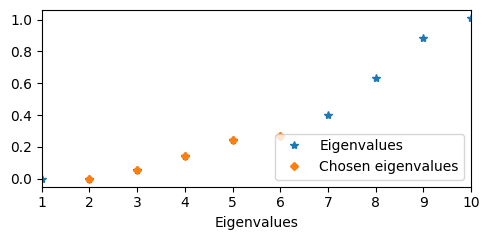

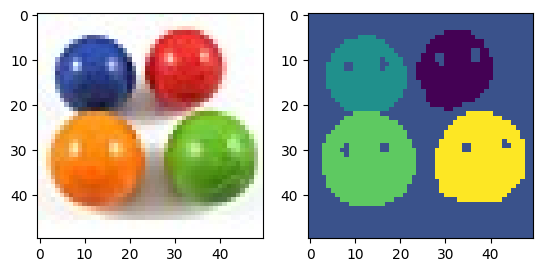

In [ ]:
image_segmentation(k=26, laplacian_normalization='unn', num_classes=5, chosen_eig_indices=[1, 2, 3, 4, 5], plot_eig=True)

zero eigen 1


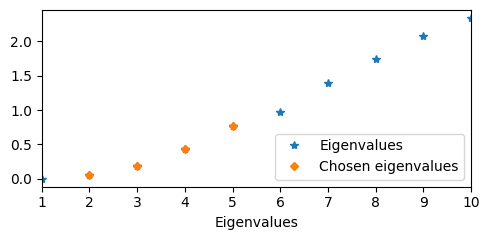

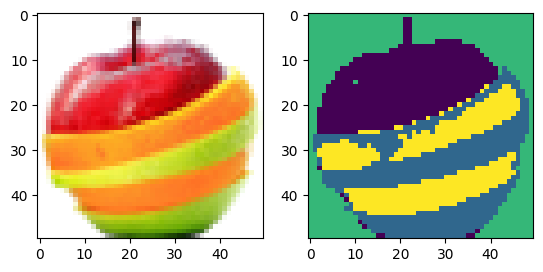

In [ ]:
image_segmentation('fruit_salad.bmp', k=35, laplacian_normalization='unn', num_classes=4, chosen_eig_indices=[1, 2, 3, 4], plot_eig=True)

As a failure mode, we can simply choose too small value of $k$ to degrade the performance. For instance, we show the example below with $k=5$, which produces a graph with 8 connected components, and thus produces worse segmentation results.

zero eigen 8


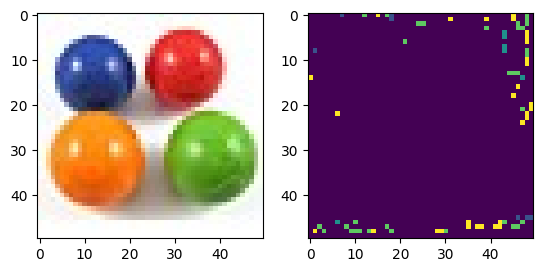

In [256]:
image_segmentation(k=5, laplacian_normalization='unn', num_classes=5, chosen_eig_indices=[1, 2, 3, 4, 5], plot_eig=False)

Another failure mode can be achieved by inorrect selection of `chosen_eig_indices`. For instance, we can skip first few eigenvectors and take only 2 instead of 4 of them, so that we intentionally lose the information on clusters that 4 eigenvectors (correct ones) would carry.

zero eigen 1


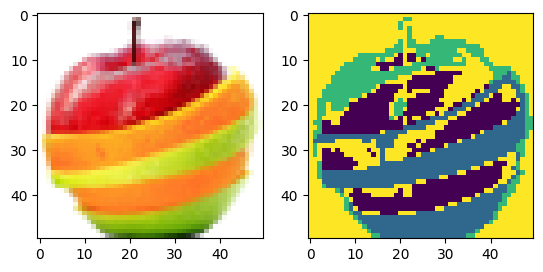

In [262]:
image_segmentation('fruit_salad.bmp', k=35, laplacian_normalization='unn', num_classes=4, chosen_eig_indices=[3, 4], plot_eig=False)

### Q3.2: A full graph built between the pixels of a 50 × 50 image corresponds to $50^2$ nodes. Solving the full eigenvalue problem in this case would scale in the order of $2^{34}$ . Even on weak hardware this takes only seconds to minutes. Segmenting a Full HD picture of 1920 × 1080 would scale in the order of $2^{64}$ (about a month on a decent machine). Beyond that, the large picture would require to store in memory a graph over millions of nodes. A full graph on that scale requires about 1TB of memory. Can you think two simple techniques to reduce the computational and occupational cost of Spectral Clustering?

We here suggest two techniques to mitigate the computational and occupational costs:
1. Image downsampling: We can resize the large image to a lower resolution (e.g. 50*50) and run spectral clustering on this reduced image. Once we obtain the segmented image at lower resolution, we can upsample it back to the original image size.
2. Sparse matrices and partial eigendecomposition: In this assignment, we used $\epsilon$- and k-NN graphs to build similarity graphs. The advantage of these methods is that they ensure that the resulting weight and Laplacian matrices are sparse. To reduce the occupational cost when working with high resolution image, we can store these matrices more efficiently by using `csr` format. Moreover, we can assume that first $k$ eigenvectors of Laplacian would be sufficient for spectral clustering, so we do not need to compute the full eigendecomposition. Instead, we can compute only those first $k$ eigenvectors and do spectral clustering with them. The computation of first eigenvectors of sparse matrix can be achieved with Lanczos method, which is supported by `scipy` library.

### Q3.3: Choose a larger image of your choice, and try to implement some of the scalability modifications to run spectral clustering on it. Report some examples of the results you achieve. 

We will now show the results of spectral clustering using both image downsampling technique. For these experiments, we use two images: 
1. A 1000*1000 image containing 3 differently colored and well separated balls on a white background, representing an easier segmentation task.
2. A 1500x1500 image containing multiple overlapping balls with 7 colors, representing a more difficult task.

Both images are shown below.

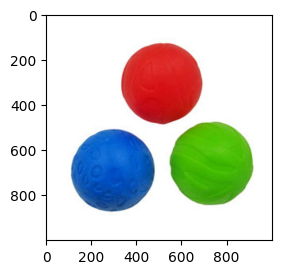

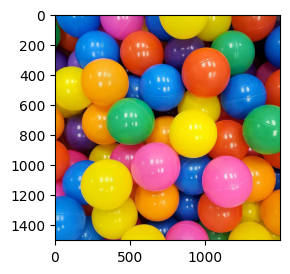

In [282]:
for i, path in enumerate(['highres.jpg', 'balls.jpg']):
    filename = os.path.join('data', path)
    X = io.imread(filename)
    X = (X - np.min(X)) / (np.max(X) - np.min(X))

    im_side = np.size(X, 1)
    Xr = X.reshape(im_side ** 2, 3)
    plt.figure()

    plt.subplot(1, 2, i+1)
    plt.imshow(X)
plt.show()

To support downsampling technique, we simply introduced a boolean flag `downsample_img`, for which, when set to `True`, the input image is resized to $50*50$ before doing the spectral clustering (in the same manner as before). After clustering, we first plot the downsampled segmentation image, then upsample it to original resolution, and lastly plot the final segmentation.

zero eigen 1


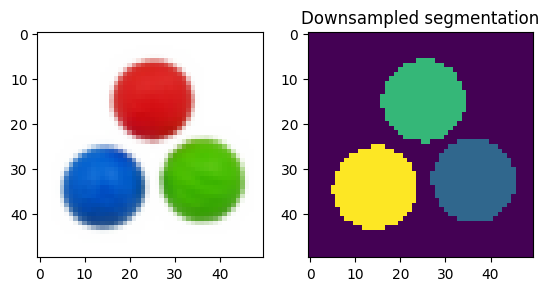

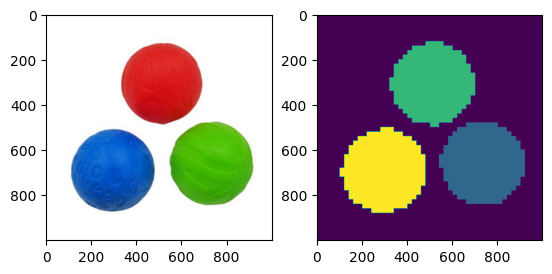

In [278]:
image_segmentation(input_img="highres.jpg", k=26, laplacian_normalization='unn', 
                num_classes=4, chosen_eig_indices=[0,1,2,3], 
                plot_eig=False, downsample_img=True, use_sparse_and_lanczos=False)


zero eigen 1


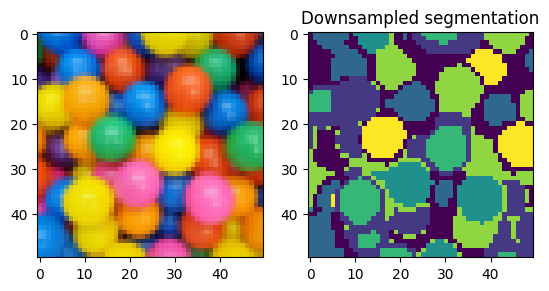

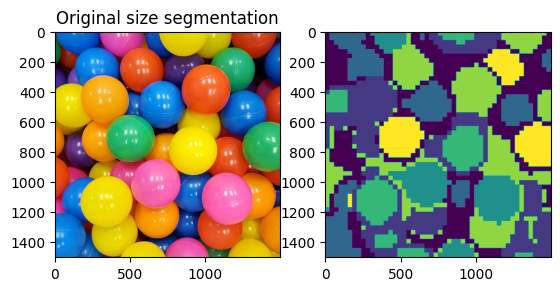

In [283]:
image_segmentation(input_img="balls.jpg", k=14, laplacian_normalization='unn', 
                num_classes=7, chosen_eig_indices=[0,1,2,3,4,5,6], 
                plot_eig=False, downsample_img=True, use_sparse_and_lanczos=False)


Our method works very well for the easier image task. For the more difficult example, the results are decent, but noticeably worse. In particular, the method struggles to distinguish visually similar colors, such as yellow and orange or blue and purple. This limitation becomes more pronounced after downsampling, since interpolation blurs the boundaries and mixes the colors of neighboring pixels. This makes the color (cluster) separation even more difficult. Another observation is that the segmented ball shapes are no longer circular. Even though some of them keep an approximately circular shape, most of them appear irregular with the line and/or staircase edges. This occurs because, in the lower reoslution image, the balls are represented by fewer pixels which are insufficient for clean boundary. Moreover, downsampling introduces aliansing which further distorts the shape and boundaries. If we used higher resolution image, this staircase artifact would be negligible and would allow for a smooth and more accurate segmentation of circular shapes. Nevertheless, since this approach is only an approximation, it can still be useful in certain simpler cases and may produce acceptable results even for more challenging images.

Unfortunately, we have not been able to show the second modification technique in practice. We first observed an out-of-memory error when attempting to allocate a similarity matrix $W$ of size $1000000*1000000$. To mitigate this, we tried to modify the `build_similarity_graph` function to avoid initializing the full matrix and instead compute its rows on the fly. However, this approach proved to be too time-consuming. As a next attempt, we tried restricting the similarity computation to $k$ nearest neighbors and constructed the similarity matrix using `lil_matrix`, which is an efficient format for constructing sparse matrices. Unfortunately, this approach also did not work properly.

If this approach were to work as intended, we would modify the `build_laplacian` function to construct the degree matrix in `csr` format. Finally, we would modify the `spectral_clustering` function to compute the eigendecomposition using `eigsh` instead of `eig`, and compute only the first $k$ eigenvalues and eigenvectors, where $k=num\_classes$. The remaining logic of the functions would stay the same.